### Import Libaries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split


## Analysis Dataset

### Dataset Overview

In [2]:
df = pd.read_csv("combined.csv")
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [3]:
print(df.shape)

(1852394, 23)


In [4]:
df.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06
mean,5.371934e+05,4.173860e+17,7.006357e+01,4.881326e+04,3.853931e+01,-9.022783e+01,8.864367e+04,1.358674e+09,3.853898e+01,-9.022794e+01,5.210015e-03
std,3.669110e+05,1.309115e+18,1.592540e+02,2.688185e+04,5.071470e+00,1.374789e+01,3.014876e+05,1.819508e+07,5.105604e+00,1.375969e+01,7.199217e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902742e+01,-1.666716e+02,0.000000e+00
25%,2.315490e+05,1.800429e+14,9.640000e+00,2.623700e+04,3.466890e+01,-9.679800e+01,7.410000e+02,1.343017e+09,3.474012e+01,-9.689944e+01,0.000000e+00
50%,4.630980e+05,3.521417e+15,4.745000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.443000e+03,1.357089e+09,3.936890e+01,-8.744069e+01,0.000000e+00
75%,8.335758e+05,4.642255e+15,8.310000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.374581e+09,4.195626e+01,-8.024511e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.992100e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.388534e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 23 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Unnamed: 0             int64  
 1   trans_date_trans_time  str    
 2   cc_num                 int64  
 3   merchant               str    
 4   category               str    
 5   amt                    float64
 6   first                  str    
 7   last                   str    
 8   gender                 str    
 9   street                 str    
 10  city                   str    
 11  state                  str    
 12  zip                    int64  
 13  lat                    float64
 14  long                   float64
 15  city_pop               int64  
 16  job                    str    
 17  dob                    str    
 18  trans_num              str    
 19  unix_time              int64  
 20  merch_lat              float64
 21  merch_long             float64
 22  is_fraud               int64 

In [6]:
print(df.columns.tolist())

['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']


#### Summery


این دیتاست شامل 1852394 رکورد تراکنش و 23 ویژگی است. 

اطلاعات موجود شامل مشخصات مشتری، جزئیات تراکنش، اطلاعات فروشنده، موقعیت جغرافیایی و متغیر هدف (is_fraud) است.

با توجه به ساختار داده‌ها، این دیتاست برای انجام تحلیل‌های اکتشافی و توسعه مدل‌های تشخیص تقلب مناسب است.

### Data Quality Assessment

#### بررسی Missing Values

In [7]:
missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percent": missing_percent
})

missing_df.sort_values("Missing Percent", ascending=False)


,Missing Count,Missing Percent
Unnamed: 0,0,0.0
trans_date_trans_time,0,0.0
cc_num,0,0.0
merchant,0,0.0
category,0,0.0
amt,0,0.0
first,0,0.0
last,0,0.0
gender,0,0.0
street,0,0.0


#### Duplicate Records

In [8]:
print( f"Duplicate Rows :{ df.duplicated().sum()}" )

Duplicate Rows :0


#### Duplicate Transaction IDs

In [9]:
print("Duplicate Transaction IDs:", df["trans_num"].duplicated().sum())

Duplicate Transaction IDs: 0


#### Cardinality of Categorical Features

In [10]:
categorical_cols = [
    "merchant",
    "category",
    "gender",
    "city",
    "state",
    "job"
]

for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values")

merchant: 693 unique values
category: 14 unique values
gender: 2 unique values
city: 906 unique values
state: 51 unique values
job: 497 unique values


#### Most Frequent Categories

In [11]:
df["category"].value_counts()

category
gas_transport     188029
grocery_pos       176191
home              175460
shopping_pos      166463
kids_pets         161727
shopping_net      139322
entertainment     134118
food_dining       130729
personal_care     130085
health_fitness    122553
misc_pos          114229
misc_net           90654
grocery_net        64878
travel             57956
Name: count, dtype: int64

In [12]:
df["state"].value_counts().head(10)

state
TX    135269
NY    119419
PA    114173
CA     80495
OH     66627
MI     65825
IL     62212
FL     60775
AL     58521
MO     54904
Name: count, dtype: int64

In [13]:
df["job"].value_counts().head(10)

job
Film/video editor             13898
Exhibition designer           13167
Surveyor, land/geomatics      12436
Naval architect               12434
Materials engineer            11711
Designer, ceramics/pottery    11688
Environmental consultant      10974
Financial adviser             10963
Systems developer             10962
IT trainer                    10943
Name: count, dtype: int64

In [14]:
df["merchant"].value_counts().head(10)

merchant
fraud_Kilback LLC        6262
fraud_Cormier LLC        5246
fraud_Schumm PLC         5195
fraud_Kuhn LLC           5031
fraud_Boyer PLC          4999
fraud_Dickinson Ltd      4953
fraud_Emard Inc          3867
fraud_Cummerata-Jones    3860
fraud_Corwin-Collins     3853
fraud_Rodriguez Group    3843
Name: count, dtype: int64

#### Unique Credit Cards

In [15]:
print("Unique Credit Cards:", df["cc_num"].nunique())

Unique Credit Cards: 999


#### Summery

هیچ مقدار گمشده‌ای (Missing Value) در ستون‌های دیتاست مشاهده نشد.

هیچ رکورد یا شناسه تراکنش تکراری وجود ندارد که نشان‌دهنده کیفیت و یکپارچگی مناسب داده‌ها است.

دیتاست شامل تنوع مناسبی از ویژگی‌های دسته‌ای مانند فروشنده، دسته‌بندی تراکنش، شغل، شهر و ایالت است که امکان انجام تحلیل‌های متنوع را فراهم می‌کند.

### Target Variable Analysis

#### Class Distribution

In [16]:
fraud_counts = df["is_fraud"].value_counts()

print(f"Normal Transactions : {fraud_counts[0]:,}")
print(f"Fraud Transactions  : {fraud_counts[1]:,}")

Normal Transactions : 1,842,743
Fraud Transactions  : 9,651


#### Class Percentage

In [17]:
fraud_percent = (df["is_fraud"].value_counts(normalize=True) * 100).round(2)

print(f"Normal Transactions : {fraud_percent[0]}%")
print(f"Fraud Transactions  : {fraud_percent[1]}%")

Normal Transactions : 99.48%
Fraud Transactions  : 0.52%


#### Class Distribution (Bar Plot)

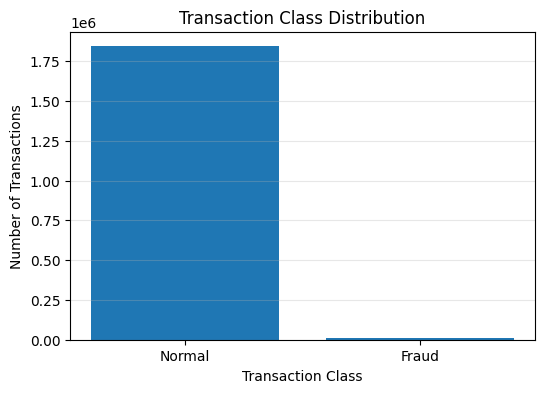

In [18]:


fraud_counts = df["is_fraud"].value_counts().sort_index()

plt.figure(figsize=(6,4))

plt.bar(
    ["Normal", "Fraud"],
    fraud_counts.values
)

plt.title("Transaction Class Distribution")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Class Distribution (Pie Chart)

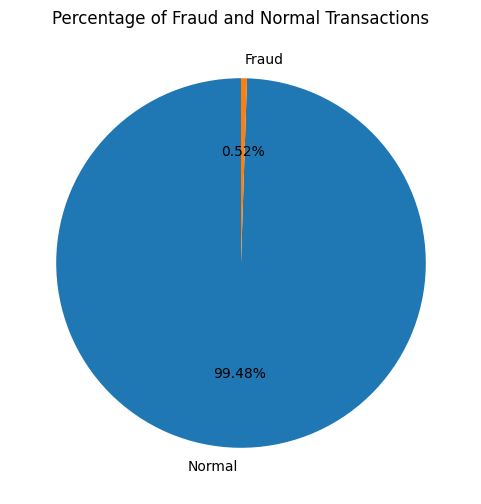

In [19]:
plt.figure(figsize=(6,6))

plt.pie(
    fraud_counts,
    labels=["Normal", "Fraud"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Percentage of Fraud and Normal Transactions")

plt.show()

#### Imbalance Ratio

In [20]:
normal = fraud_counts[0]
fraud = fraud_counts[1]

print(f"Imbalance Ratio (Normal : Fraud) = {normal/fraud:.1f} : 1")

Imbalance Ratio (Normal : Fraud) = 190.9 : 1


###### یعنی به ازای هر 190 تراکنش عادی یک تقلب وجود دارد

#### Summery

دیتاست شامل 1,842,743 تراکنش عادی و 9,651 تراکنش تقلبی است.

تنها 0.52 درصد از کل تراکنش‌ها تقلبی هستند؛ بنابراین دیتاست دارای عدم توازن (Class Imbalance) قابل توجهی است.

این عدم توازن باید در مراحل بعدی تحلیل و مدل‌سازی مورد توجه قرار گیرد.

### Numerical Feature Analysis

#### Summary Statistics

In [21]:
numerical_features = [
    "amt",
    "city_pop"
]

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
amt,1852394.0,70.063567,159.253975,1.0,9.64,47.45,83.1,28948.9
city_pop,1852394.0,88643.674509,301487.618344,23.0,741.00,2443.00,20328.0,2906700.0


#### Distribution of Numerical Features

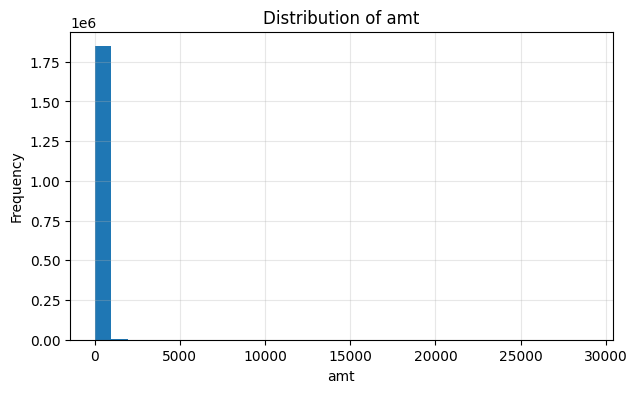

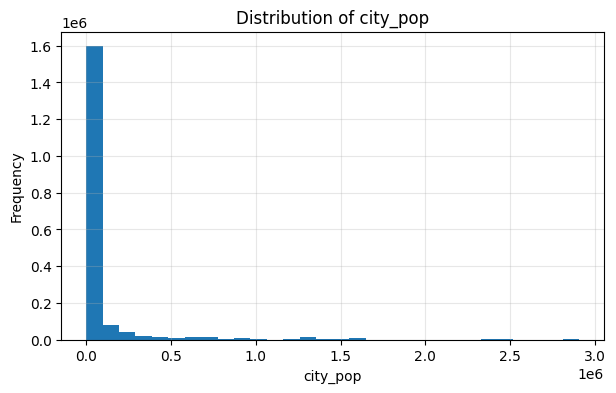

In [22]:
for col in numerical_features:
    plt.figure(figsize=(7,4))

    plt.hist(df[col], bins=30)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.grid(alpha=0.3)

    plt.show()

#### Boxplots

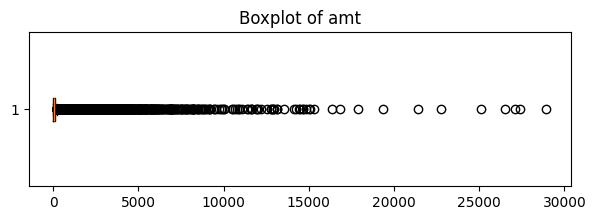

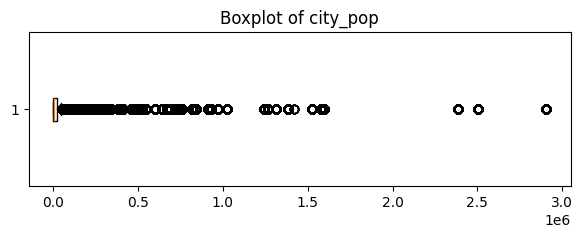

In [23]:
for col in numerical_features:

    plt.figure(figsize=(7,2))

    plt.boxplot(df[col], vert=False)

    plt.title(f"Boxplot of {col}")

    plt.show()

#### Skewness

In [24]:
df[numerical_features].skew().sort_values(ascending=False)

amt         40.812809
city_pop     5.590805
dtype: float64

###### The amt feature is highly right-skewed, indicating that most transactions involve relatively small amounts, while a small number of transactions have exceptionally high values. Similarly, city_pop is positively skewed, suggesting that most customers reside in small or medium-sized cities, with relatively few living in highly populated urban areas.

#### Correlation Analysis

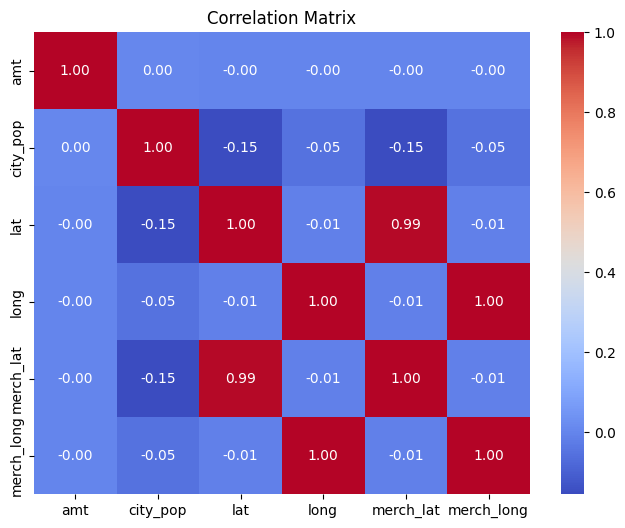

In [25]:
corr_features = [
    "amt",
    "city_pop",
    "lat",
    "long",
    "merch_lat",
    "merch_long"
]

plt.figure(figsize=(8,6))

sns.heatmap(
    df[corr_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

#### Summery

توزیع ویژگی مبلغ تراکنش (amt) دارای چولگی مثبت شدیدی است؛ به این معنا که بیشتر تراکنش‌ها مبالغ کمی دارند و تعداد کمی تراکنش با مبالغ بسیار بالا مشاهده می‌شود.

ویژگی جمعیت شهر (city_pop) نیز دارای چولگی مثبت است که نشان می‌دهد بخش عمده مشتریان در شهرهای کوچک یا متوسط زندگی می‌کنند.

در هر دو ویژگی، مقادیر پرت (Outliers) مشاهده شد که در تحلیل‌های بعدی باید مورد توجه قرار گیرند.

بررسی همبستگی بین ویژگی‌های عددی، رابطه غیرعادی یا بسیار قوی‌ای را نشان نداد.

### Categorical Feature Analysis

#### Summary of Categorical Features

In [26]:
categorical_features = [
    "gender",
    "category",
    "merchant",
    "state",
    "city",
    "job"
]

for col in categorical_features:
    print(f"{col}: {df[col].nunique()} unique values")

gender: 2 unique values
category: 14 unique values
merchant: 693 unique values
state: 51 unique values
city: 906 unique values
job: 497 unique values


#### Gender Distribution

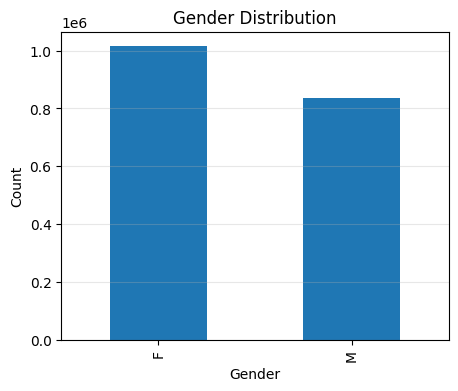

In [27]:
plt.figure(figsize=(5,4))

df["gender"].value_counts().plot(kind="bar")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Top 10 Transaction Categories

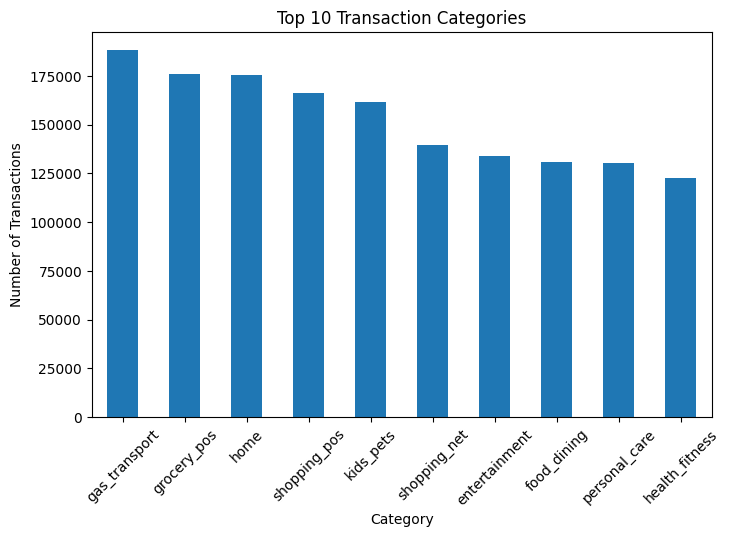

In [28]:
plt.figure(figsize=(8,5))

df["category"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Transaction Categories")
plt.xlabel("Category")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)

plt.show()

#### Top 10 Merchants

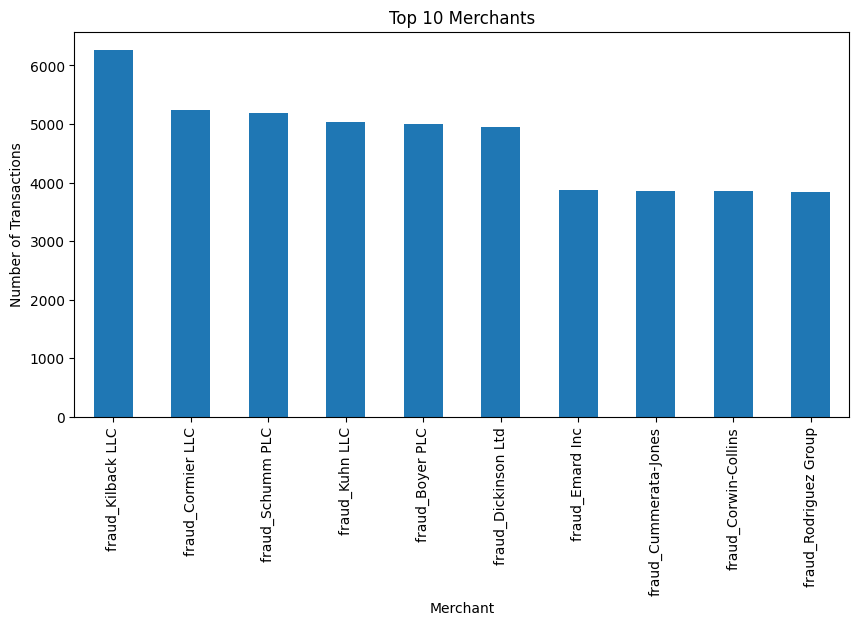

In [29]:
plt.figure(figsize=(10,5))

df["merchant"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Merchants")
plt.xlabel("Merchant")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=90)

plt.show()

#### Top 10 States

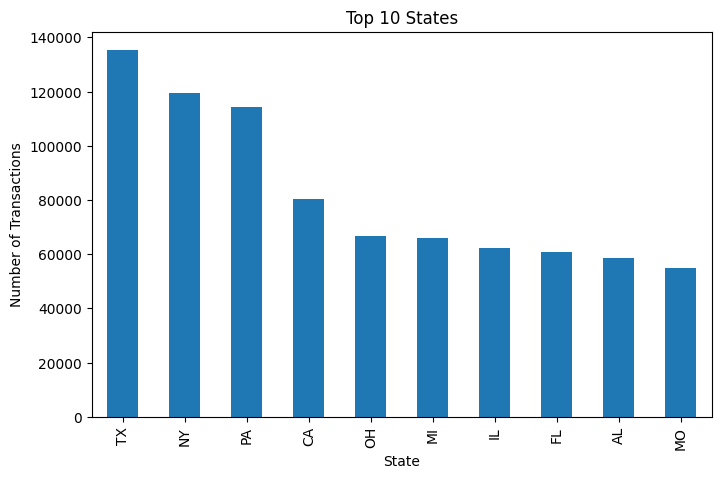

In [30]:
plt.figure(figsize=(8,5))

df["state"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 States")
plt.xlabel("State")
plt.ylabel("Number of Transactions")

plt.show()

#### Top 10 Cities

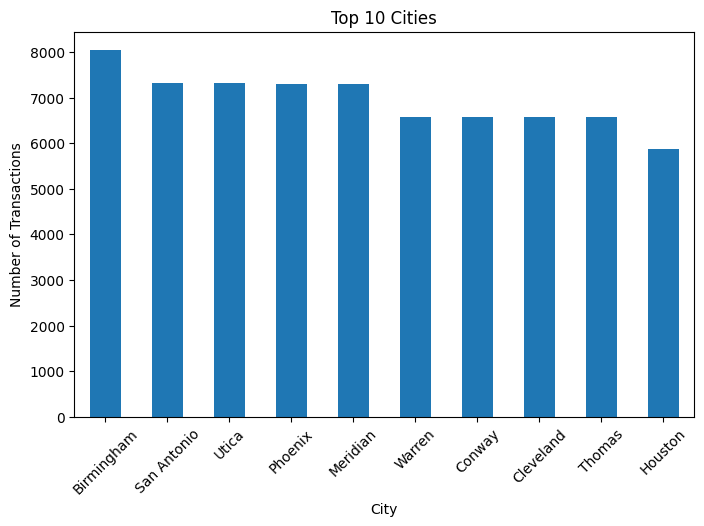

In [31]:
plt.figure(figsize=(8,5))

df["city"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Cities")
plt.xlabel("City")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)

plt.show()

#### Top 10 Occupations

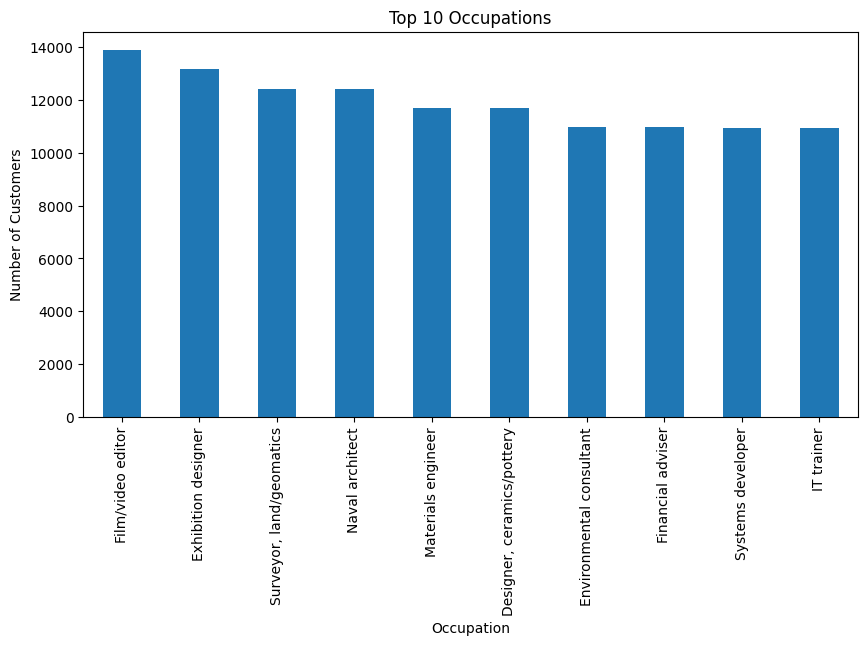

In [32]:
plt.figure(figsize=(10,5))

df["job"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Occupations")
plt.xlabel("Occupation")
plt.ylabel("Number of Customers")

plt.xticks(rotation=90)

plt.show()

#### Summery

ویژگی‌های دسته‌ای شامل فروشنده، دسته‌بندی تراکنش، شغل، شهر و ایالت از تنوع مناسبی برخوردار هستند.

توزیع این ویژگی‌ها یکنواخت نیست و برخی مقادیر نسبت به سایرین فراوانی بیشتری دارند.

این بررسی دید اولیه‌ای از ساختار داده فراهم می‌کند و زمینه را برای تحلیل‌های دقیق‌تر در مراحل بعدی آماده می‌سازد.

## Time-Based Transaction Analysis

### Part 1 - DateTime Conversion

In [33]:
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])

In [34]:
df["trans_date_trans_time"].dtype

dtype('<M8[us]')

#### Summary

ستون trans_date_trans_time با موفقیت به فرمت DateTime تبدیل شد. این تبدیل امکان انجام تحلیل‌های زمانی و استخراج ویژگی‌های مرتبط با زمان را فراهم می‌کند.

### Part 2 - Feature Engineering

In [35]:
df["year"] = df["trans_date_trans_time"].dt.year
df["month"] = df["trans_date_trans_time"].dt.month
df["month_name"] = df["trans_date_trans_time"].dt.month_name()

df["day"] = df["trans_date_trans_time"].dt.day

df["hour"] = df["trans_date_trans_time"].dt.hour

df["day_of_week"] = df["trans_date_trans_time"].dt.dayofweek
df["day_name"] = df["trans_date_trans_time"].dt.day_name()

df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

In [36]:
df[
    [
        "trans_date_trans_time",
        "year",
        "month",
        "month_name",
        "day",
        "hour",
        "day_of_week",
        "day_name",
        "is_weekend",
    ]
].head()

,trans_date_trans_time,year,month,month_name,day,hour,day_of_week,day_name,is_weekend
0,2019-01-01 00:00:18,2019,1,January,1,0,1,Tuesday,0
1,2019-01-01 00:00:44,2019,1,January,1,0,1,Tuesday,0
2,2019-01-01 00:00:51,2019,1,January,1,0,1,Tuesday,0
3,2019-01-01 00:01:16,2019,1,January,1,0,1,Tuesday,0
4,2019-01-01 00:03:06,2019,1,January,1,0,1,Tuesday,0


In [37]:
df["trans_date_trans_time"].min()

Timestamp('2019-01-01 00:00:18')

In [38]:
df["trans_date_trans_time"].max()

Timestamp('2020-12-31 23:59:34')

#### Summary

ویژگی‌های زمانی شامل سال، ماه، نام ماه، روز، ساعت، روز هفته، نام روز هفته و شاخص آخر هفته استخراج شدند. این ویژگی‌ها در ادامه برای تحلیل روند زمانی تراکنش‌ها و بررسی ارتباط زمان با وقوع تقلب مورد استفاده قرار خواهند گرفت.

### Part 3 - Monthly Transaction Analysis

#### Monthly Transaction Count

In [39]:
months_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly_fraud_rate = (
    df.groupby("month_name")["is_fraud"]
      .mean()
      .mul(100)
      .reindex(months_order)
)

In [40]:
monthly_fraud = (
    df[df["is_fraud"] == 1]
      .groupby("month_name")
      .size()
      .reindex(months_order)
)

In [41]:
monthly_transactions = (
    df.groupby("month_name")
      .size()
      .reindex([
          "January","February","March","April","May","June",
          "July","August","September","October","November","December"
      ])
)

In [42]:
monthly_transactions_df = (
    monthly_transactions
    .reset_index()
    .rename(columns={
        "month_name": "Month",
        0: "Transaction Count"
    })
)

monthly_transactions_df

,Month,Transaction Count
0,January,104727
1,February,97657
2,March,143789
3,April,134970
4,May,146875
5,June,173869
6,July,172444
7,August,176118
8,September,140185
9,October,138106


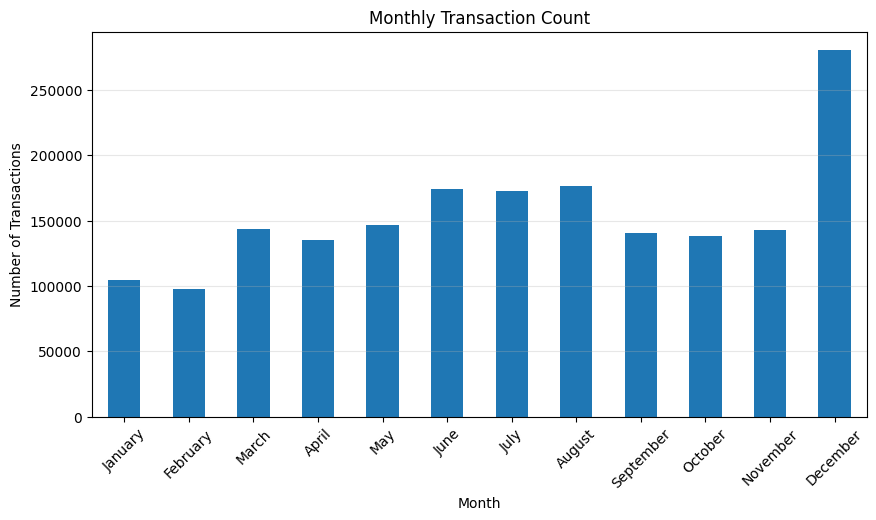

In [43]:
plt.figure(figsize=(10,5))

monthly_transactions.plot(kind="bar")

plt.title("Monthly Transaction Count")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Monthly Fraud Count

In [44]:
monthly_fraud_df = (
    monthly_fraud
    .reset_index()
    .rename(columns={
        "month_name": "Month",
        0: "Fraud Count"
    })
)

monthly_fraud_df

,Month,Fraud Count
0,January,849
1,February,853
2,March,938
3,April,678
4,May,935
5,June,821
6,July,652
7,August,797
8,September,758
9,October,838


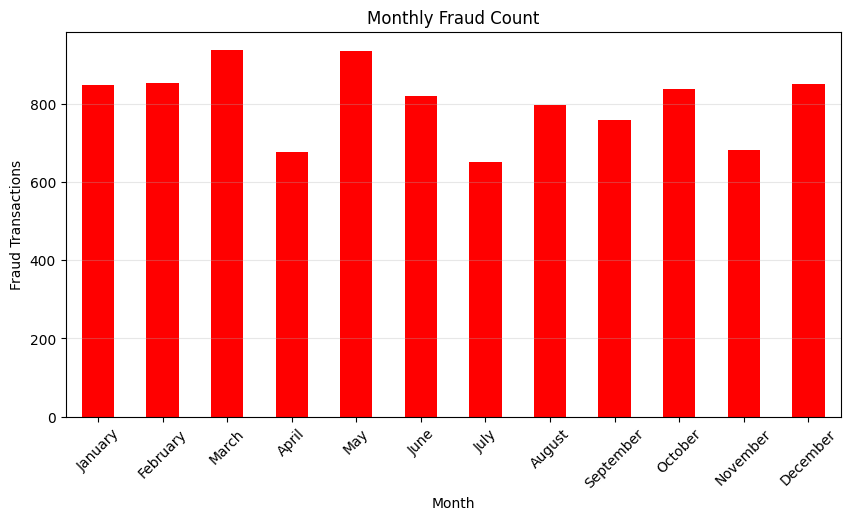

In [45]:
plt.figure(figsize=(10,5))

monthly_fraud.plot(kind="bar", color="red")

plt.title("Monthly Fraud Count")
plt.xlabel("Month")
plt.ylabel("Fraud Transactions")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Monthly Fraud Rate

In [46]:
monthly_fraud_rate_df = (
    monthly_fraud_rate
    .reset_index()
    .rename(columns={
        "month_name": "Month",
        "is_fraud": "Fraud Rate (%)"
    })
)

monthly_fraud_rate_df["Fraud Rate (%)"] = monthly_fraud_rate_df["Fraud Rate (%)"].round(2)
monthly_fraud_rate_df

,Month,Fraud Rate (%)
0,January,0.81
1,February,0.87
2,March,0.65
3,April,0.50
4,May,0.64
5,June,0.47
6,July,0.38
7,August,0.45
8,September,0.54
9,October,0.61


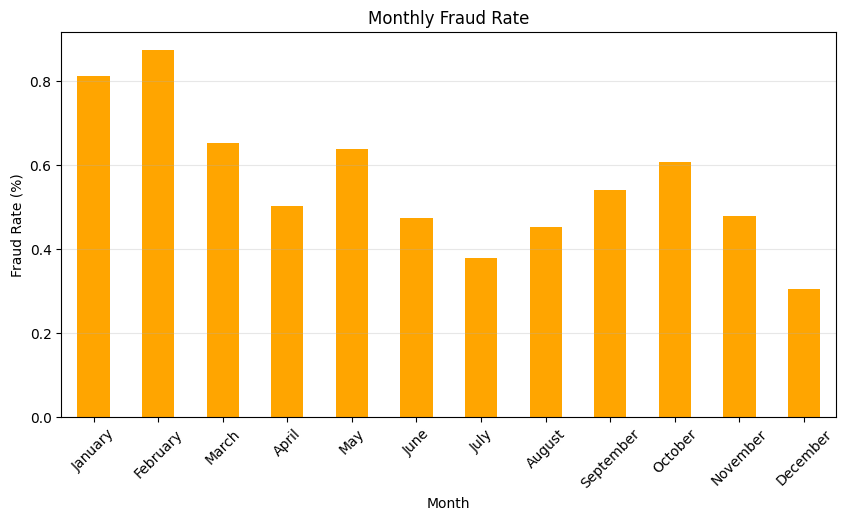

In [47]:
plt.figure(figsize=(10,5))

monthly_fraud_rate.plot(kind="bar", color="orange")

plt.title("Monthly Fraud Rate")
plt.xlabel("Month")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Summary
تعداد تراکنش‌ها در ماه‌های مختلف مورد بررسی قرار گرفت.

تعداد و نرخ تراکنش‌های تقلبی برای هر ماه محاسبه شد.

استفاده از نرخ تقلب، مقایسه دقیق‌تری نسبت به تعداد خام تقلب بین ماه‌ها فراهم می‌کند.

این تحلیل می‌تواند الگوهای زمانی وقوع تقلب را آشکار کرده و در طراحی سیستم‌های نظارتی و مدل‌های تشخیص تقلب مورد استفاده قرار گیرد.

### Part 4 - Weekly Transaction Analysis

#### Weekly Transaction Count

In [48]:
df["day_name"] = df["trans_date_trans_time"].dt.day_name()

In [49]:
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_transactions = (
    df.groupby("day_name")
      .size()
      .reindex(days_order)
)

weekly_transactions_df = (
    weekly_transactions
    .reset_index()
    .rename(columns={
        "day_name": "Day",
        0: "Transaction Count"
    })
)

weekly_transactions_df

,Day,Transaction Count
0,Monday,369418
1,Tuesday,270340
2,Wednesday,183913
3,Thursday,206741
4,Friday,215078
5,Saturday,263227
6,Sunday,343677


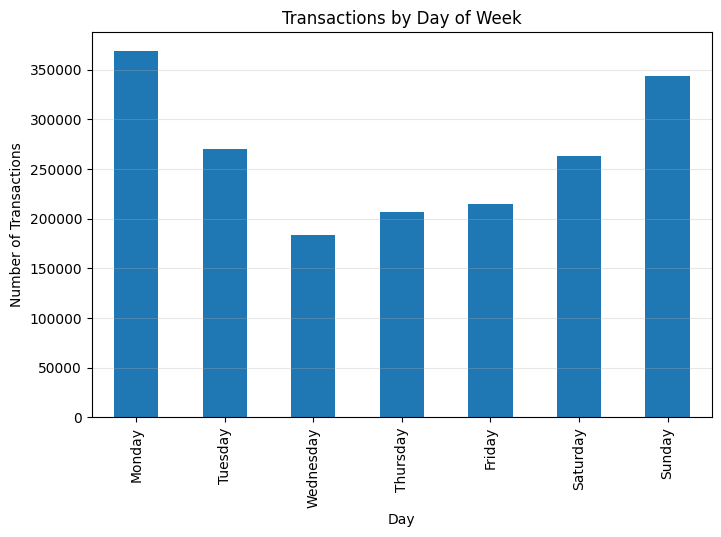

In [50]:
plt.figure(figsize=(8,5))

weekly_transactions.plot(kind="bar")

plt.title("Transactions by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Transactions")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Weekly Fraud Count

In [51]:
weekly_fraud = (
    df[df["is_fraud"] == 1]
    .groupby("day_name")
    .size()
    .reindex(days_order)
)

weekly_fraud_df = (
    weekly_fraud
    .reset_index()
    .rename(columns={
        "day_name": "Day",
        0: "Fraud Count"
    })
)

weekly_fraud_df

,Day,Fraud Count
0,Monday,1484
1,Tuesday,1266
2,Wednesday,1125
3,Thursday,1317
4,Friday,1376
5,Saturday,1493
6,Sunday,1590


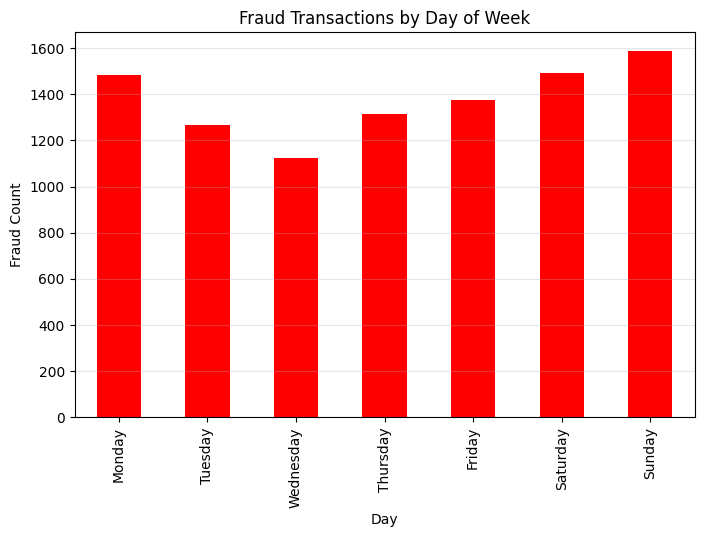

In [52]:
plt.figure(figsize=(8,5))

weekly_fraud.plot(kind="bar", color="red")

plt.title("Fraud Transactions by Day of Week")
plt.xlabel("Day")
plt.ylabel("Fraud Count")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Weekly Fraud Rate

In [53]:
weekly_fraud_rate = (
    df.groupby("day_name")["is_fraud"]
      .mean()
      .mul(100)
      .reindex(days_order)
)

weekly_fraud_rate_df = (
    weekly_fraud_rate
    .reset_index()
    .rename(columns={
        "day_name": "Day",
        "is_fraud": "Fraud Rate (%)"
    })
)

weekly_fraud_rate_df["Fraud Rate (%)"] = (
    weekly_fraud_rate_df["Fraud Rate (%)"]
    .round(2)
)

weekly_fraud_rate_df

,Day,Fraud Rate (%)
0,Monday,0.40
1,Tuesday,0.47
2,Wednesday,0.61
3,Thursday,0.64
4,Friday,0.64
5,Saturday,0.57
6,Sunday,0.46


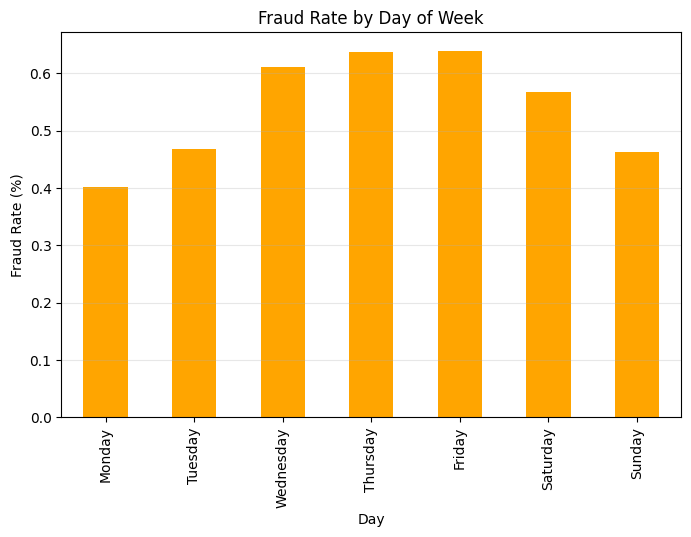

In [54]:
plt.figure(figsize=(8,5))

weekly_fraud_rate.plot(kind="bar", color="orange")

plt.title("Fraud Rate by Day of Week")
plt.xlabel("Day")
plt.ylabel("Fraud Rate (%)")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Weekend vs Weekday

In [55]:
df["is_weekend"] = df["day_of_week"].isin([5,6]).astype(int)

In [56]:
weekend_analysis = (
    df.groupby("is_weekend")["is_fraud"]
      .agg(
          total_transactions="count",
          fraud_transactions="sum",
          fraud_rate="mean"
      )
)

weekend_analysis["fraud_rate"] *= 100

weekend_analysis

,total_transactions,fraud_transactions,fraud_rate
is_weekend,,,
0,1245490,6568,0.527343
1,606904,3083,0.507988


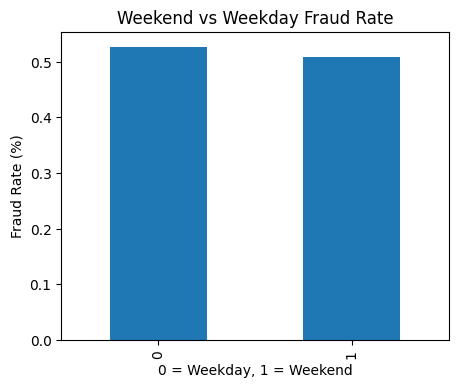

In [57]:
plt.figure(figsize=(5,4))

weekend_analysis["fraud_rate"].plot(kind="bar")

plt.title("Weekend vs Weekday Fraud Rate")
plt.xlabel("0 = Weekday, 1 = Weekend")
plt.ylabel("Fraud Rate (%)")

plt.show()

#### Summary
تعداد تراکنش‌ها و نرخ تقلب در روزهای مختلف هفته بررسی شد.

تفاوت بین روزهای کاری و آخر هفته تحلیل شد.

این تحلیل می‌تواند الگوهای زمانی مرتبط با رفتار مشتریان و تراکنش‌های تقلبی را مشخص کند.

### Part 5 - Hourly Transaction Analysis

#### Hourly Transaction Count

In [58]:
hourly_transactions = (
    df.groupby("hour")
      .size()
)

hourly_transactions_df = (
    hourly_transactions
    .reset_index()
    .rename(columns={
        "hour": "Hour",
        0: "Transaction Count"
    })
)

hourly_transactions_df

,Hour,Transaction Count
0,0,60655
1,1,61330
2,2,60796
3,3,60968
4,4,59938
5,5,60088
6,6,60406
7,7,60301
8,8,60498
9,9,60231


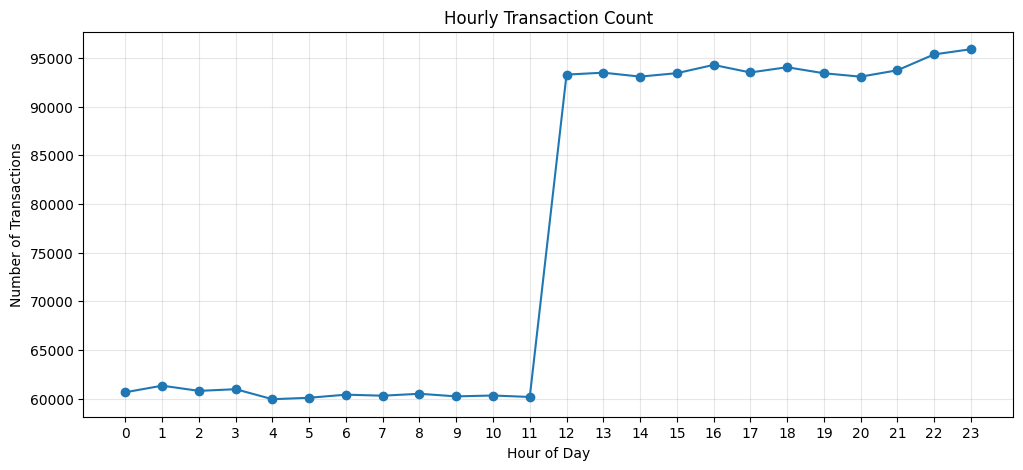

In [59]:
plt.figure(figsize=(12,5))

plt.plot(
    hourly_transactions.index,
    hourly_transactions.values,
    marker="o"
)

plt.title("Hourly Transaction Count")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")

plt.xticks(range(24))

plt.grid(alpha=0.3)

plt.show()

#### Hourly Fraud Count

In [60]:
hourly_fraud = (
    df[df["is_fraud"] == 1]
    .groupby("hour")
    .size()
)

hourly_fraud_df = (
    hourly_fraud
    .reset_index()
    .rename(columns={
        "hour": "Hour",
        0: "Fraud Count"
    })
)

hourly_fraud_df

,Hour,Fraud Count
0,0,823
1,1,827
2,2,793
3,3,803
4,4,61
5,5,80
6,6,54
7,7,72
8,8,59
9,9,61


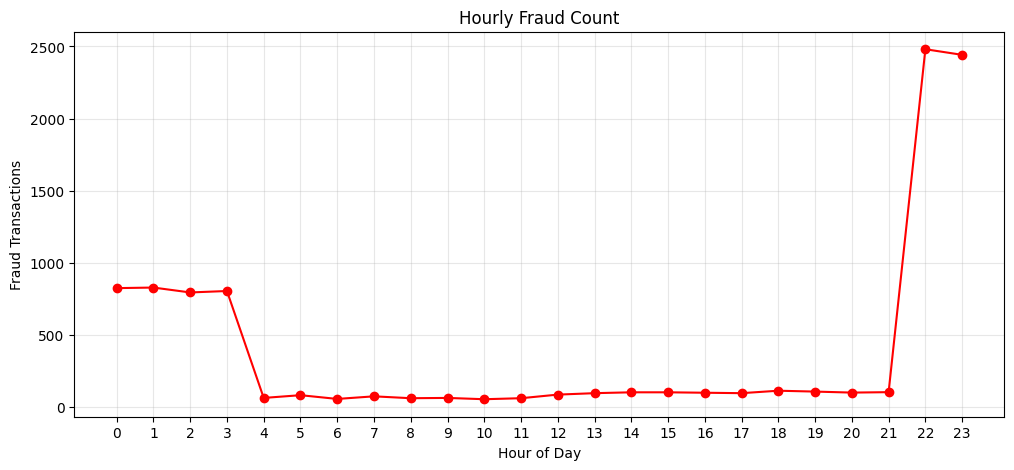

In [61]:
plt.figure(figsize=(12,5))

plt.plot(
    hourly_fraud.index,
    hourly_fraud.values,
    marker="o",
    color="red"
)

plt.title("Hourly Fraud Count")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Transactions")

plt.xticks(range(24))

plt.grid(alpha=0.3)

plt.show()

#### Hourly Fraud Rate

In [62]:
hourly_fraud_rate = (
    df.groupby("hour")["is_fraud"]
      .mean()
      .mul(100)
)

hourly_fraud_rate_df = (
    hourly_fraud_rate
    .reset_index()
    .rename(columns={
        "hour": "Hour",
        "is_fraud": "Fraud Rate (%)"
    })
)

hourly_fraud_rate_df["Fraud Rate (%)"] = (
    hourly_fraud_rate_df["Fraud Rate (%)"]
    .round(2)
)

hourly_fraud_rate_df

,Hour,Fraud Rate (%)
0,0,1.36
1,1,1.35
2,2,1.30
3,3,1.32
4,4,0.10
5,5,0.13
6,6,0.09
7,7,0.12
8,8,0.10
9,9,0.10


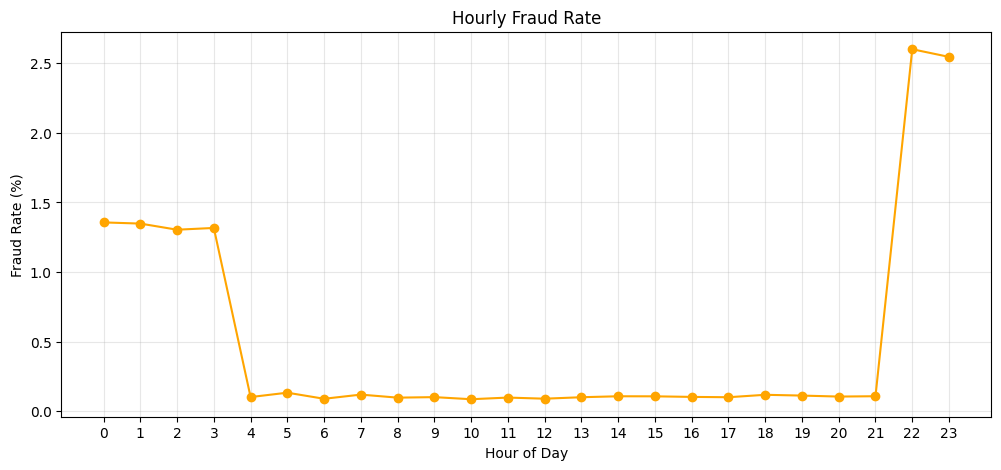

In [63]:
plt.figure(figsize=(12,5))

plt.plot(
    hourly_fraud_rate.index,
    hourly_fraud_rate.values,
    marker="o",
    color="orange"
)

plt.title("Hourly Fraud Rate")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")

plt.xticks(range(24))

plt.grid(alpha=0.3)

plt.show()

### Part 6 - Time Trend Analysis

#### Daily Transaction Trend

In [64]:
df["transaction_date"] = df["trans_date_trans_time"].dt.date

In [65]:
daily_transactions = (
    df.groupby("transaction_date")
      .size()
      .reset_index(name="Transaction Count")
)

daily_transactions.head()

,transaction_date,Transaction Count
0,2019-01-01,2414
1,2019-01-02,1118
2,2019-01-03,1236
3,2019-01-04,1474
4,2019-01-05,1409


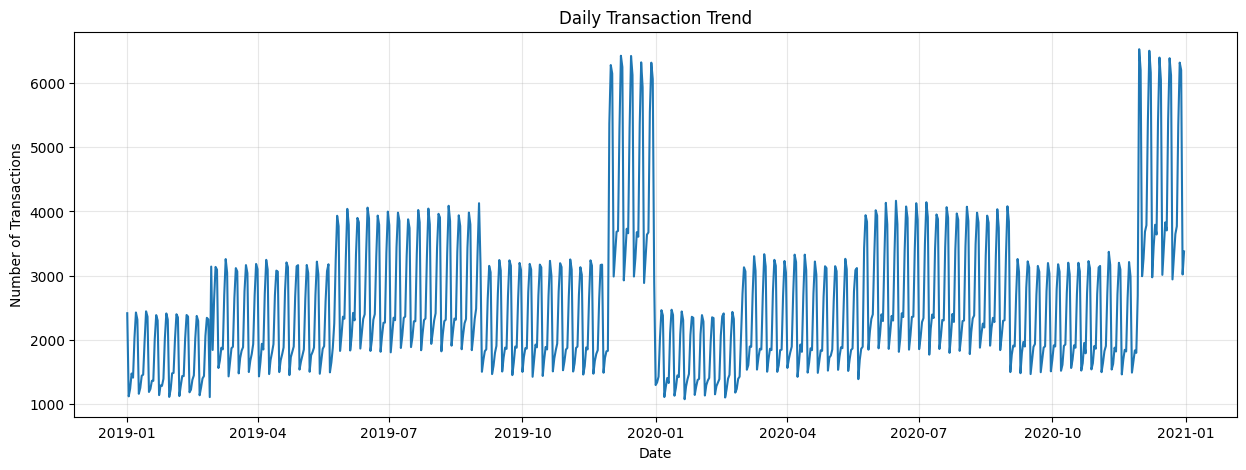

In [66]:
plt.figure(figsize=(15,5))

plt.plot(
    daily_transactions["transaction_date"],
    daily_transactions["Transaction Count"]
)

plt.title("Daily Transaction Trend")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")

plt.grid(alpha=0.3)

plt.show()

#### Daily Fraud Trend

In [67]:
daily_fraud = (
    df[df["is_fraud"] == 1]
    .groupby("transaction_date")
    .size()
    .reset_index(name="Fraud Count")
)

daily_fraud.head()

,transaction_date,Fraud Count
0,2019-01-02,7
1,2019-01-03,12
2,2019-01-04,13
3,2019-01-05,13
4,2019-01-06,2


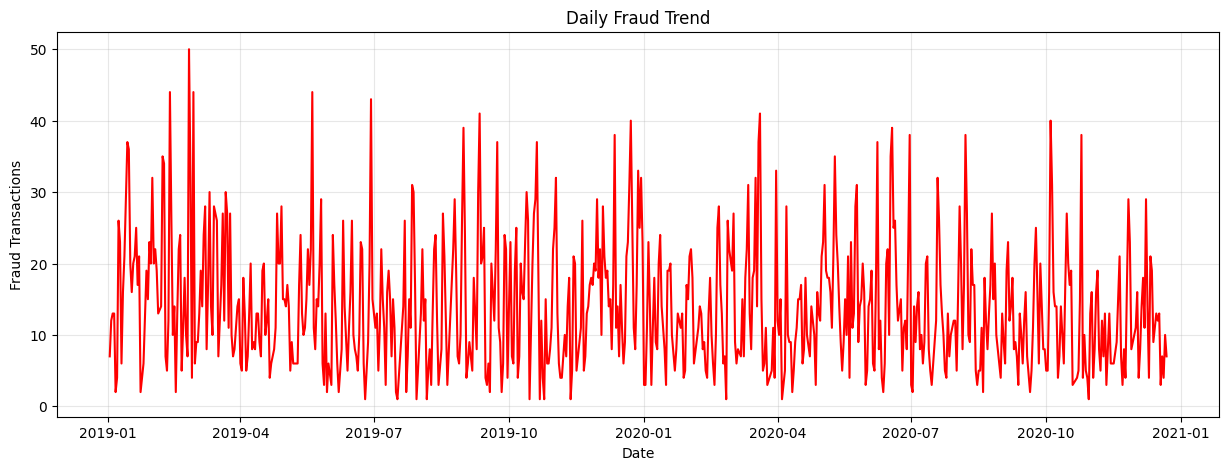

In [68]:
plt.figure(figsize=(15,5))

plt.plot(
    daily_fraud["transaction_date"],
    daily_fraud["Fraud Count"],
    color="red"
)

plt.title("Daily Fraud Trend")
plt.xlabel("Date")
plt.ylabel("Fraud Transactions")

plt.grid(alpha=0.3)

plt.show()

#### Daily Fraud Rate

In [69]:
daily_fraud_rate = (
    df.groupby("transaction_date")["is_fraud"]
      .mean()
      .mul(100)
      .reset_index(name="Fraud Rate (%)")
)

daily_fraud_rate["Fraud Rate (%)"] = (
    daily_fraud_rate["Fraud Rate (%)"]
    .round(2)
)

daily_fraud_rate.head()

,transaction_date,Fraud Rate (%)
0,2019-01-01,0.00
1,2019-01-02,0.63
2,2019-01-03,0.97
3,2019-01-04,0.88
4,2019-01-05,0.92


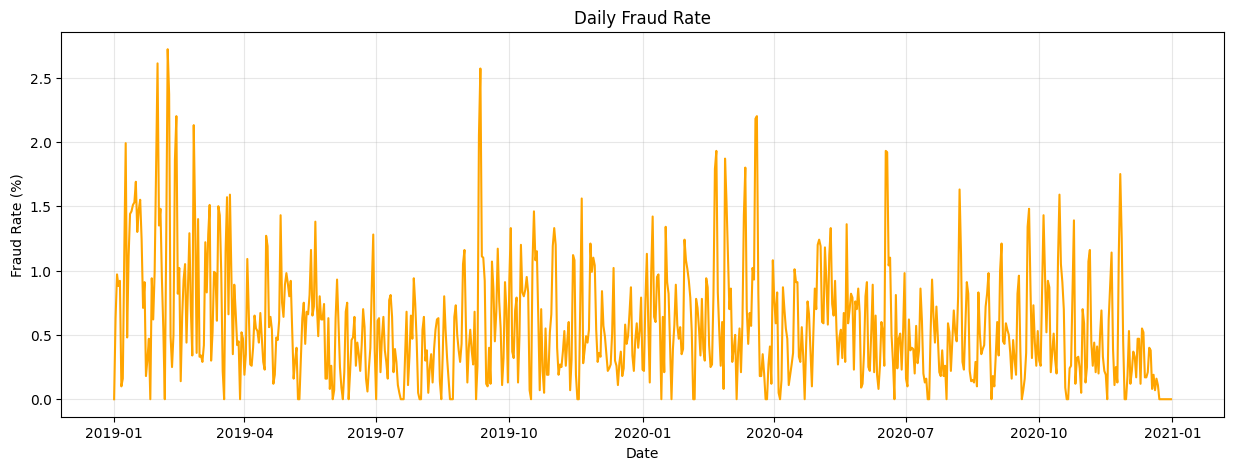

In [70]:
plt.figure(figsize=(15,5))

plt.plot(
    daily_fraud_rate["transaction_date"],
    daily_fraud_rate["Fraud Rate (%)"],
    color="orange"
)

plt.title("Daily Fraud Rate")
plt.xlabel("Date")
plt.ylabel("Fraud Rate (%)")

plt.grid(alpha=0.3)

plt.show()

#### Moving Average

In [71]:
daily_transactions["7-Day Moving Average"] = (
    daily_transactions["Transaction Count"]
    .rolling(window=7)
    .mean()
)

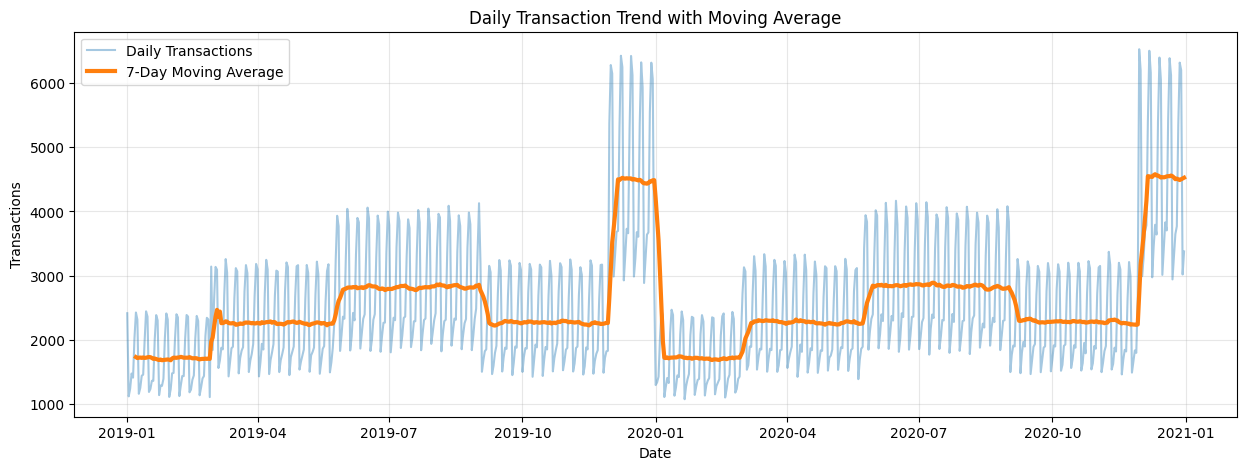

In [72]:
plt.figure(figsize=(15,5))

plt.plot(
    daily_transactions["transaction_date"],
    daily_transactions["Transaction Count"],
    alpha=0.4,
    label="Daily Transactions"
)

plt.plot(
    daily_transactions["transaction_date"],
    daily_transactions["7-Day Moving Average"],
    linewidth=3,
    label="7-Day Moving Average"
)

plt.title("Daily Transaction Trend with Moving Average")
plt.xlabel("Date")
plt.ylabel("Transactions")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

#### Summary
روند روزانه تعداد تراکنش‌ها، تعداد تقلب و نرخ تقلب بررسی شد.

تغییرات زمانی و نوسانات حجم تراکنش‌ها در طول دوره ثبت داده‌ها تحلیل شد.

استفاده از میانگین متحرک، روند کلی تراکنش‌ها را بدون تأثیر نوسانات روزانه نمایش داد.

این تحلیل می‌تواند برای شناسایی تغییرات غیرعادی و الگوهای زمانی مرتبط با تقلب مورد استفاده قرار گیرد.

### Part 7 - Time Period Analysis

#### Feature Engineering

In [73]:
def get_time_period(hour):
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

df["time_period"] = (
    df["trans_date_trans_time"]
      .dt.hour
      .apply(get_time_period)
)

#### Transaction Count by Time Period

In [74]:
period_order = ["Night", "Morning", "Afternoon", "Evening"]

period_transactions = (
    df.groupby("time_period")
      .size()
      .reindex(period_order)
      .reset_index(name="Transaction Count")
)

period_transactions

,time_period,Transaction Count
0,Night,363775
1,Morning,361926
2,Afternoon,561117
3,Evening,565576


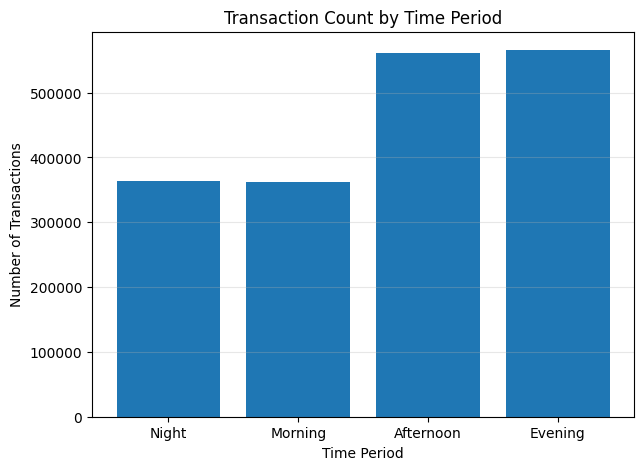

In [75]:
plt.figure(figsize=(7,5))

plt.bar(
    period_transactions["time_period"],
    period_transactions["Transaction Count"]
)

plt.title("Transaction Count by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Transactions")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Fraud Count by Time Period

In [76]:
period_fraud = (
    df[df["is_fraud"] == 1]
      .groupby("time_period")
      .size()
      .reindex(period_order)
      .reset_index(name="Fraud Count")
)

period_fraud

,time_period,Fraud Count
0,Night,3387
1,Morning,357
2,Afternoon,569
3,Evening,5338


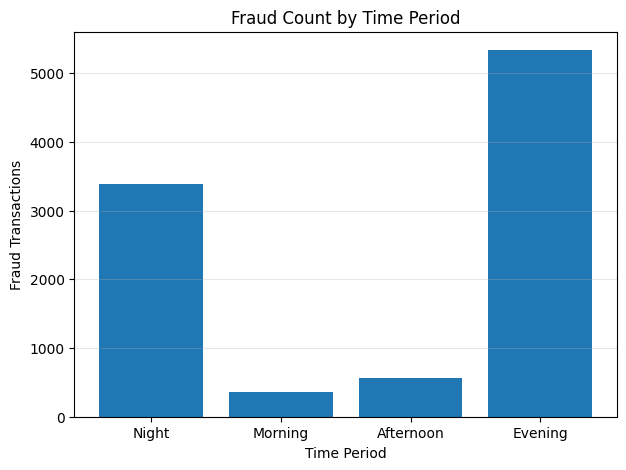

In [77]:
plt.figure(figsize=(7,5))

plt.bar(
    period_fraud["time_period"],
    period_fraud["Fraud Count"],
)

plt.title("Fraud Count by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Fraud Transactions")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Fraud Rate by Time Period

In [78]:
period_fraud_rate = (
    df.groupby("time_period")["is_fraud"]
      .mean()
      .mul(100)
      .reindex(period_order)
      .reset_index(name="Fraud Rate (%)")
)

period_fraud_rate["Fraud Rate (%)"] = (
    period_fraud_rate["Fraud Rate (%)"]
    .round(2)
)

period_fraud_rate

,time_period,Fraud Rate (%)
0,Night,0.93
1,Morning,0.10
2,Afternoon,0.10
3,Evening,0.94


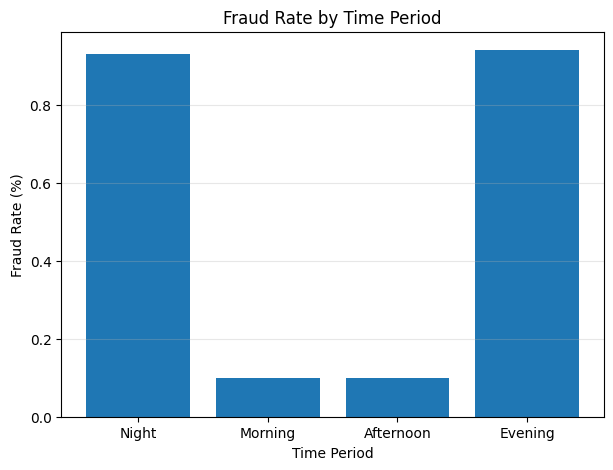

In [79]:
plt.figure(figsize=(7,5))

plt.bar(
    period_fraud_rate["time_period"],
    period_fraud_rate["Fraud Rate (%)"]
)

plt.title("Fraud Rate by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Fraud Rate (%)")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Summary
شبانه‌روز به چهار بازه زمانی شامل Night، Morning، Afternoon و Evening تقسیم شد.

تعداد تراکنش‌ها، تعداد تقلب‌ها و نرخ تقلب برای هر بازه زمانی محاسبه و مقایسه شد.

این تحلیل می‌تواند الگوهای زمانی مرتبط با رفتار مشتریان و تراکنش‌های مشکوک را آشکار کند و در طراحی سیستم‌های پایش بلادرنگ (Real-Time Monitoring) و قوانین تشخیص تقلب مورد استفاده قرار گیرد.

### Part 8 – Hour × Weekday Fraud Heatmap

#### Create Time Features

In [80]:

# Convert to datetime
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])

# Correct weekday order
days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Extract hour
df["hour"] = df["trans_date_trans_time"].dt.hour

# Extract weekday
df["day_name"] = pd.Categorical(
    df["trans_date_trans_time"].dt.day_name(),
    categories=days_order,
    ordered=True
)

#### Fraud Count Heatmap

In [81]:
fraud_count = (
    df[df["is_fraud"] == 1]
    .pivot_table(
        index="hour",
        columns="day_name",
        values="is_fraud",
        aggfunc="count",
        fill_value=0
    )
    .reindex(index=range(24), columns=days_order, fill_value=0)
)

fraud_count

day_name,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
hour,,,,,,,
0,128,106,95,128,110,126,130
1,125,104,92,126,110,137,133
2,114,105,87,105,128,127,127
3,142,110,98,82,109,125,137
4,6,13,4,12,11,7,8
5,10,14,8,14,9,14,11
6,10,10,5,3,8,7,11
7,16,4,10,12,9,7,14
8,12,8,5,7,9,7,11


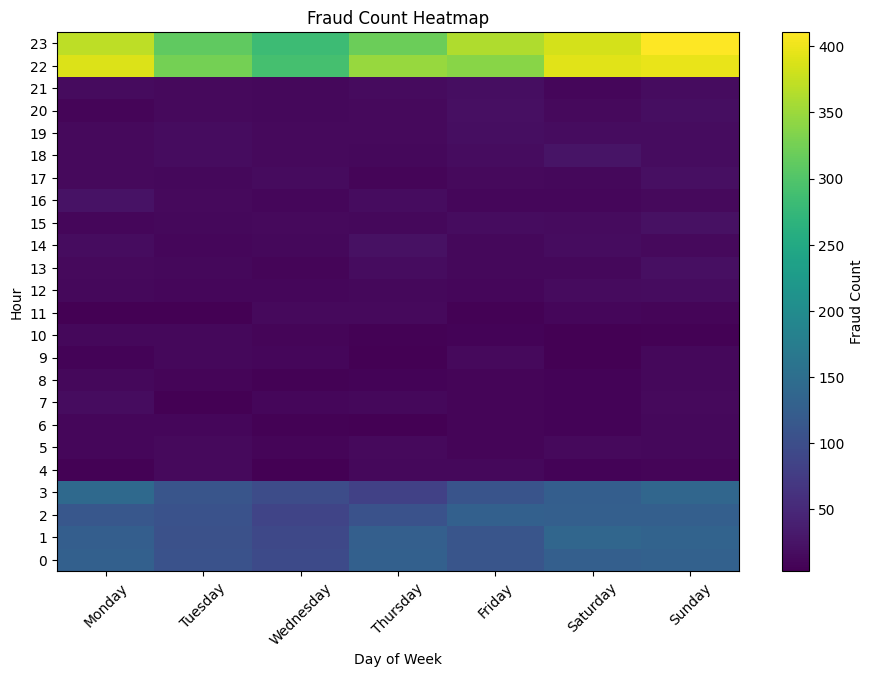

In [82]:
plt.figure(figsize=(11,7))

plt.imshow(
    fraud_count,
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Fraud Count")

plt.xticks(
    range(len(days_order)),
    days_order,
    rotation=45
)

plt.yticks(range(24))

plt.xlabel("Day of Week")
plt.ylabel("Hour")
plt.title("Fraud Count Heatmap")

plt.show()

#### Fraud Rate Heatmap

In [83]:
total_transactions = (
    df.pivot_table(
        index="hour",
        columns="day_name",
        values="is_fraud",
        aggfunc="count",
        fill_value=0
    )
    .reindex(index=range(24), columns=days_order, fill_value=0)
)

fraud_rate = (
    fraud_count / total_transactions
) * 100

fraud_rate = fraud_rate.fillna(0).round(2)

fraud_rate

day_name,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
hour,,,,,,,
0,1.06,1.22,1.56,1.85,1.55,1.45,1.17
1,1.01,1.16,1.49,1.87,1.55,1.58,1.17
2,0.96,1.18,1.44,1.53,1.78,1.48,1.13
3,1.16,1.25,1.60,1.20,1.55,1.43,1.22
4,0.05,0.15,0.07,0.18,0.16,0.08,0.07
5,0.08,0.16,0.13,0.20,0.13,0.16,0.10
6,0.08,0.11,0.08,0.04,0.11,0.08,0.10
7,0.13,0.05,0.17,0.18,0.13,0.08,0.13
8,0.10,0.09,0.08,0.10,0.13,0.08,0.10


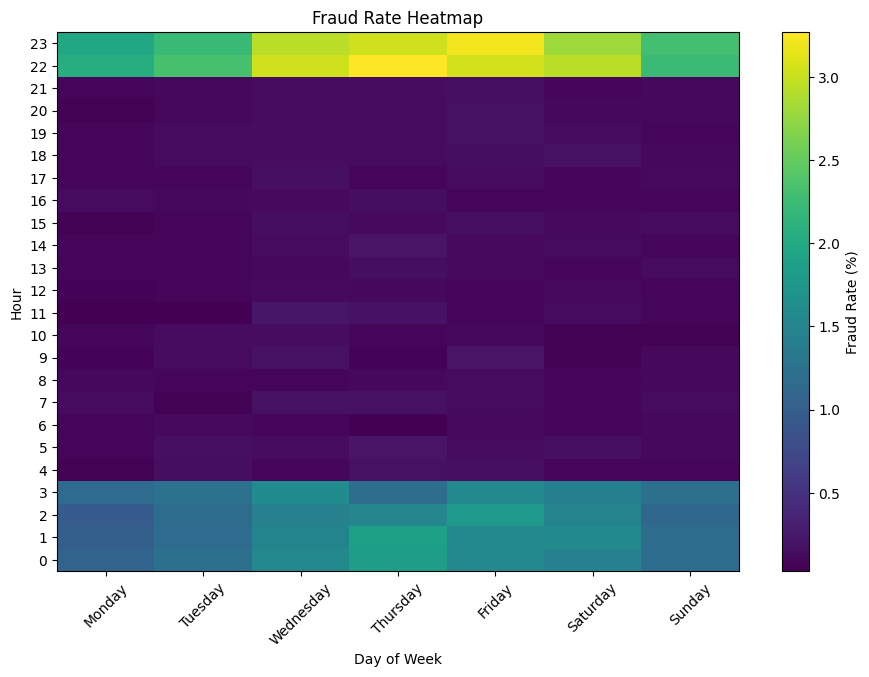

In [84]:
plt.figure(figsize=(11,7))

plt.imshow(
    fraud_rate,
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Fraud Rate (%)")

plt.xticks(
    range(len(days_order)),
    days_order,
    rotation=45
)

plt.yticks(range(24))

plt.xlabel("Day of Week")
plt.ylabel("Hour")
plt.title("Fraud Rate Heatmap")

plt.show()

#### Summary

در این بخش، الگوی زمانی تراکنش‌های تقلبی بر اساس ساعت شبانه‌روز و روزهای هفته بررسی شد. ابتدا تعداد تراکنش‌های تقلبی و سپس نرخ تقلب برای هر ترکیب ساعت و روز هفته محاسبه و به صورت Heatmap نمایش داده شد. مقایسه این دو نمودار امکان شناسایی بازه‌های زمانی با بیشترین حجم تقلب و همچنین بیشترین احتمال وقوع تقلب را فراهم می‌کند و می‌تواند در بهبود سیستم‌های تشخیص تقلب و پایش لحظه‌ای مورد استفاده قرار گیرد.

### Part 9 – Transaction Interval Analysis

#### Step 1 – Prepare Transaction Time

In [97]:
df_interval = df.copy()

df_interval["trans_date_trans_time"] = pd.to_datetime(
    df_interval["trans_date_trans_time"]
)

##### یک کپی از دیتاست می‌سازیم تا Featureهای مربوط به این تحلیل روی دیتاست اصلی تأثیر نگذارند.

#### Step 2 - Sort Transactions

In [98]:
df_interval = df_interval.sort_values(
    by=["cc_num", "trans_date_trans_time"]
)

#### Step 3 - Calculate Transaction Interval

In [99]:
df_interval["time_diff"] = (
    df_interval
    .groupby("cc_num")["trans_date_trans_time"]
    .diff()
)

#### Step 4 -  Convert Interval to Minutes

In [100]:
df_interval["time_diff_minutes"] = (
    df_interval["time_diff"]
    .dt.total_seconds() / 60
)

#### Step 5 - Transaction Interval Summary

In [101]:
df_interval["time_diff_minutes"].describe()

count    1.851395e+06
mean     5.156580e+02
std      7.554832e+02
min      0.000000e+00
25%      9.496667e+01
50%      2.615833e+02
75%      6.355833e+02
max      2.235785e+04
Name: time_diff_minutes, dtype: float64

#### Step 6 - Compare Fraudulent and Normal Transactions

In [102]:
interval_summary = (
    df_interval
    .groupby("is_fraud")["time_diff_minutes"]
    .describe()
)

interval_summary

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1841835.0,516.506903,756.143993,0.000000,95.633333,262.383333,636.116667,22357.85
1,9560.0,352.109032,592.836390,0.016667,24.345833,81.916667,478.525000,14417.95


#### Step 7 - Compare Average Interval

In [103]:
normal_mean = (
    df_interval.loc[
        df_interval["is_fraud"] == 0,
        "time_diff_minutes"
    ].mean()
)

fraud_mean = (
    df_interval.loc[
        df_interval["is_fraud"] == 1,
        "time_diff_minutes"
    ].mean()
)

print(f"Normal Mean Interval: {normal_mean:.2f} minutes")
print(f"Fraud Mean Interval: {fraud_mean:.2f} minutes")

Normal Mean Interval: 516.51 minutes
Fraud Mean Interval: 352.11 minutes


اینجا میتوانیم نتیجه بگیریم که تراکنش های تقلبی رد میانگین زمانی کوتاه تری اتفاق می افتند.

#### Step 8 - Distribution of Transaction Intervals

In [104]:
filtered_interval = df_interval[
    df_interval["time_diff_minutes"] <= 1440
]

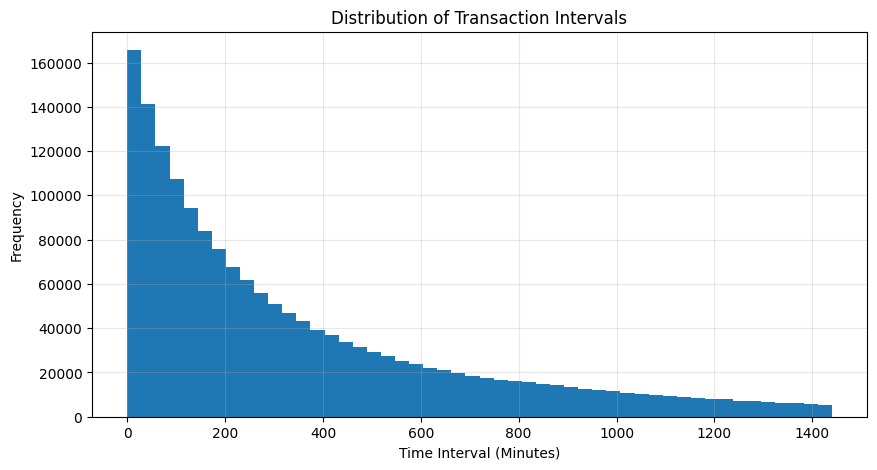

In [105]:
plt.figure(figsize=(10,5))

plt.hist(
    filtered_interval["time_diff_minutes"].dropna(),
    bins=50
)

plt.title("Distribution of Transaction Intervals")
plt.xlabel("Time Interval (Minutes)")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

این نمودار نشان می‌دهد بیشتر تراکنش‌ها با چه فاصله زمانی نسبت به تراکنش قبلی انجام شده‌اند.

مثلاً اگر بخش بزرگی از نمودار نزدیک صفر باشد، یعنی تراکنش‌های متوالی زیادی با فاصله کوتاه انجام شده‌اند.

#### Step 9 - Fraud vs Normal Comparison Box Plot

C:\Users\Legion\AppData\Local\Temp\ipykernel_17748\218796568.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


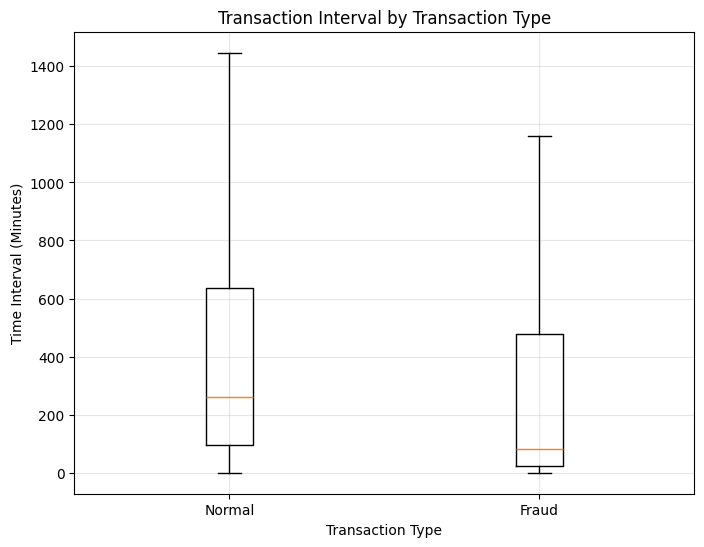

In [106]:
normal_intervals = df_interval.loc[
    df_interval["is_fraud"] == 0,
    "time_diff_minutes"
].dropna()

fraud_intervals = df_interval.loc[
    df_interval["is_fraud"] == 1,
    "time_diff_minutes"
].dropna()

plt.figure(figsize=(8, 6))

plt.boxplot(
    [normal_intervals, fraud_intervals],
    labels=["Normal", "Fraud"],
    showfliers=False
)

plt.title("Transaction Interval by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Time Interval (Minutes)")

plt.grid(alpha=0.3)

plt.show()

#### Step 10 – Transaction Interval and Fraud Rate

In [107]:
df_interval["interval_group"] = pd.cut(
    df_interval["time_diff_minutes"],
    bins=[0, 5, 15, 30, 60, 180, 360, 720, 1440],
    labels=[
        "0-5 min",
        "5-15 min",
        "15-30 min",
        "30-60 min",
        "1-3 hours",
        "3-6 hours",
        "6-12 hours",
        "12-24 hours"
    ],
    include_lowest=True
)

#### Step 11 – Calculate Fraud Rate by Interval

In [108]:
interval_fraud_rate = (
    df_interval
    .groupby("interval_group", observed=False)["is_fraud"]
    .mean() * 100
)

interval_fraud_rate

interval_group
0-5 min        2.053820
5-15 min       1.708996
15-30 min      1.381189
30-60 min      0.968619
1-3 hours      0.422763
3-6 hours      0.240959
6-12 hours     0.259052
12-24 hours    0.586106
Name: is_fraud, dtype: float64

در اینجا هر بازه نرخ تقلب را نشان میدهد.
همانظور که میبینید در باز های کتر نرخ تقلب بالاتر است.

#### Step 12 – Fraud Rate Visualization

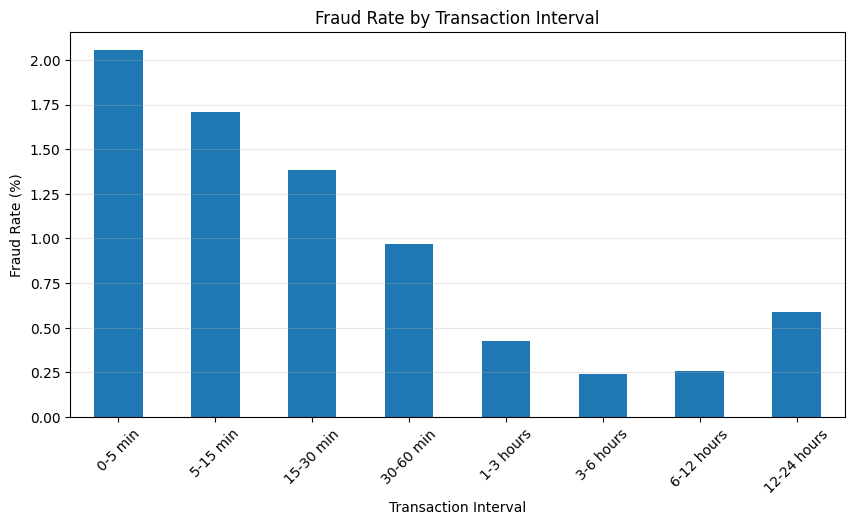

In [109]:
plt.figure(figsize=(10, 5))

interval_fraud_rate.plot(kind="bar")

plt.title("Fraud Rate by Transaction Interval")
plt.xlabel("Transaction Interval")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Step 13 – Check Very Short Intervals

In [110]:
short_interval = df_interval[
    df_interval["time_diff_minutes"] <= 5
]

print("Transactions with interval <= 5 minutes:", len(short_interval))

print(
    "Fraud Rate:",
    short_interval["is_fraud"].mean() * 100
)

Transactions with interval <= 5 minutes: 30918
Fraud Rate: 2.053819781357138


اینجا مشخص کردیم تراکنش‌هایی که حداکثر ۵ دقیقه بعد از تراکنش قبلی انجام شده‌اند، چه نرخ تقلبی دارند.

#### Step 14 – Save the New Feature

In [111]:
df["time_diff_minutes"] = df_interval["time_diff_minutes"]

### Part 10 – Transaction Amount Analysis

#### Step 1 – Create Date Feature

In [112]:
df["transaction_date"] = (
    df["trans_date_trans_time"].dt.date
)
df[[
    "cc_num",
    "trans_date_trans_time",
    "transaction_date",
    "amt",
    "is_fraud"
]].head()

,cc_num,trans_date_trans_time,transaction_date,amt,is_fraud
0,2703186189652095,2019-01-01 00:00:18,2019-01-01,4.97,0
1,630423337322,2019-01-01 00:00:44,2019-01-01,107.23,0
2,38859492057661,2019-01-01 00:00:51,2019-01-01,220.11,0
3,3534093764340240,2019-01-01 00:01:16,2019-01-01,45.00,0
4,375534208663984,2019-01-01 00:03:06,2019-01-01,41.96,0


#### Step 2 – Daily Customer Statistics

In [113]:
customer_daily = (
    df.groupby(["cc_num", "transaction_date"])
    .agg(
        transaction_count=("amt", "count"),
        total_amount=("amt", "sum"),
        average_amount=("amt", "mean"),
        median_amount=("amt", "median"),
        max_amount=("amt", "max"),
        std_amount=("amt", "std"),
        fraud_count=("is_fraud", "sum")
    )
    .reset_index()
)

In [114]:
customer_daily.head()

,cc_num,transaction_date,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count
0,60416207185,2019-01-01,1,7.27,7.2700,7.270,7.27,NaN,0
1,60416207185,2019-01-02,4,196.99,49.2475,43.865,82.08,24.410390,0
2,60416207185,2019-01-03,2,15.30,7.6500,7.650,8.43,1.103087,0
3,60416207185,2019-01-04,2,143.85,71.9250,71.925,117.11,63.901240,0
4,60416207185,2019-01-05,2,110.18,55.0900,55.090,105.20,70.866242,0


#### Step 3 – Calculate Daily Fraud Rate

In [115]:
customer_daily["fraud_rate"] = (
    customer_daily["fraud_count"]
    / customer_daily["transaction_count"]
) * 100

In [116]:
customer_daily[
    [
        "cc_num",
        "transaction_date",
        "transaction_count",
        "total_amount",
        "average_amount",
        "max_amount",
        "std_amount",
        "fraud_count",
        "fraud_rate"
    ]
].head(10)

,cc_num,transaction_date,transaction_count,total_amount,average_amount,max_amount,std_amount,fraud_count,fraud_rate
0,60416207185,2019-01-01,1,7.27,7.2700,7.27,NaN,0,0.0
1,60416207185,2019-01-02,4,196.99,49.2475,82.08,24.410390,0,0.0
2,60416207185,2019-01-03,2,15.30,7.6500,8.43,1.103087,0,0.0
3,60416207185,2019-01-04,2,143.85,71.9250,117.11,63.901240,0,0.0
4,60416207185,2019-01-05,2,110.18,55.0900,105.20,70.866242,0,0.0
5,60416207185,2019-01-06,1,102.47,102.4700,102.47,NaN,0,0.0
6,60416207185,2019-01-07,1,204.15,204.1500,204.15,NaN,0,0.0
7,60416207185,2019-01-08,3,346.56,115.5200,200.77,74.326133,0,0.0
8,60416207185,2019-01-09,2,128.80,64.4000,76.33,16.871568,0,0.0
9,60416207185,2019-01-10,1,1.90,1.9000,1.90,NaN,0,0.0


#### Step 4 – Daily Transaction Frequency

In [117]:
customer_daily["transaction_count"].describe()

count    554286.000000
mean          3.341946
std           2.514782
min           1.000000
25%           1.000000
50%           3.000000
75%           4.000000
max          36.000000
Name: transaction_count, dtype: float64

بررسی کنیم مشتری‌ها معمولاً در یک روز چند تراکنش انجام می‌دهند.

#### Step 5 – Distribution of Daily Transactions

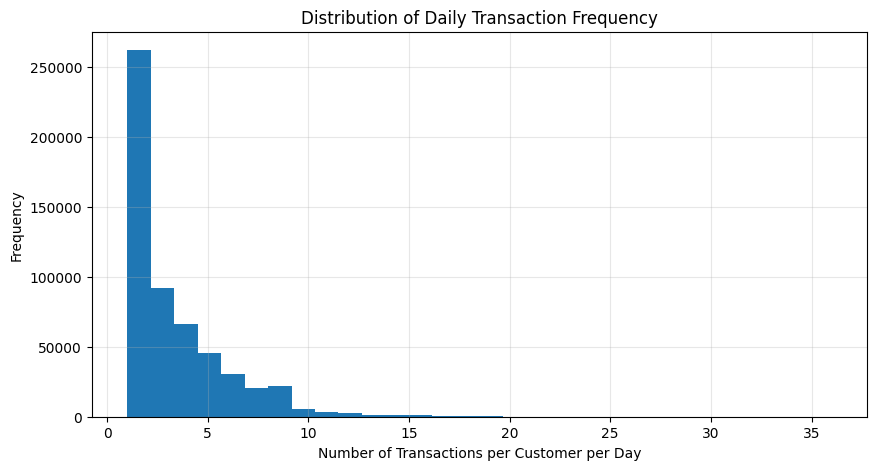

In [118]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_daily["transaction_count"],
    bins=30
)

plt.title("Distribution of Daily Transaction Frequency")
plt.xlabel("Number of Transactions per Customer per Day")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

#### Step 6 – Daily Transaction Frequency vs Fraud

In [119]:
frequency_fraud = (
    customer_daily
    .groupby("transaction_count")["fraud_rate"]
    .mean()
)

frequency_fraud.head(20)

transaction_count
1     0.060584
2     0.134043
3     0.290414
4     0.524301
5     0.763560
6     0.859890
7     0.856877
8     1.005747
9     0.977275
10    0.631883
11    0.449438
12    0.347072
13    0.128700
14    0.000000
15    0.298954
16    0.403226
17    0.000000
18    0.000000
19    0.000000
20    0.000000
Name: fraud_rate, dtype: float64

هرچه تعداد تراکنش‌های یک مشتری در یک روز بیشتر شود، نرخ تقلب هم بیشتر می‌شود

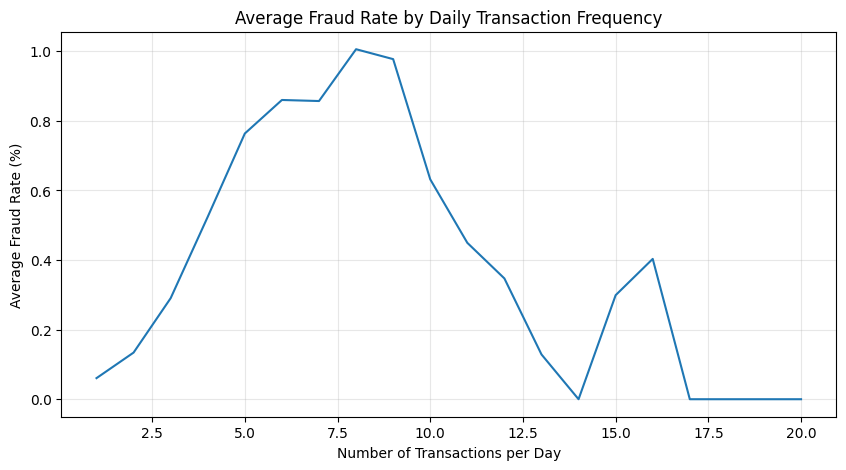

In [120]:
plt.figure(figsize=(10, 5))

frequency_fraud.head(20).plot()

plt.title("Average Fraud Rate by Daily Transaction Frequency")
plt.xlabel("Number of Transactions per Day")
plt.ylabel("Average Fraud Rate (%)")

plt.grid(alpha=0.3)

plt.show()


این نمودار به ما می‌گوید:

آیا مشتری‌هایی که در یک روز تراکنش‌های بیشتری دارند، Fraud Rate بالاتری دارند؟

#### Step 7 – Daily Total Amount

In [121]:
customer_daily["total_amount"].describe()

count    554286.000000
mean        234.148674
std         372.761773
min           1.000000
25%          65.850000
50%         144.250000
75%         283.380000
max       29347.170000
Name: total_amount, dtype: float64

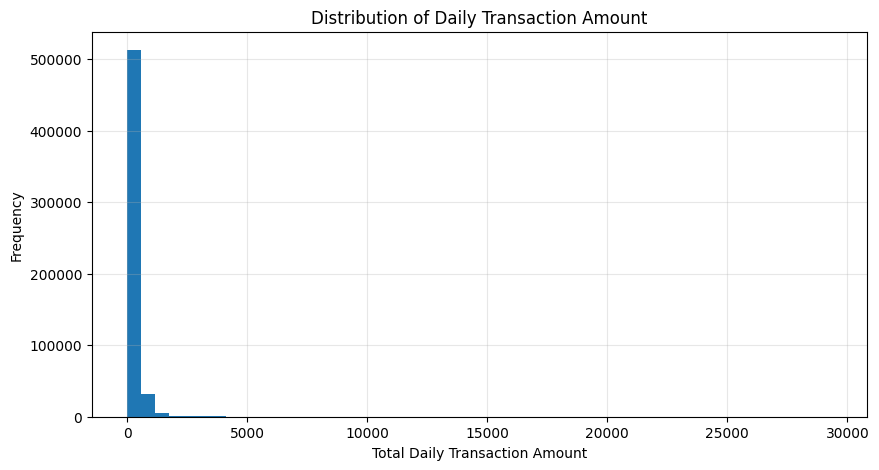

In [122]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_daily["total_amount"],
    bins=50
)

plt.title("Distribution of Daily Transaction Amount")
plt.xlabel("Total Daily Transaction Amount")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

بیشتر مشتری‌ها در یک روز مجموع تراکنش نسبتاً پایینی دارند و مجموع مبالغ بسیار بالا نسبتاً نادر است.

#### Step 8 – Daily Average Amount
این نمودار رفتار مبلغی مشتری‌ها را در سطح روز نشان می‌دهد.
هر تراکنش آن روز به طور متوسط چقدر بوده؟

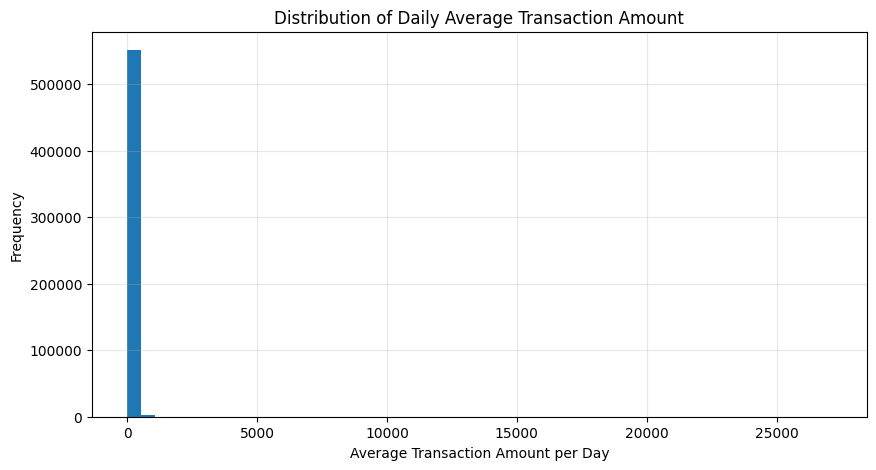

In [123]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_daily["average_amount"],
    bins=50
)

plt.title("Distribution of Daily Average Transaction Amount")
plt.xlabel("Average Transaction Amount per Day")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

#### Step 9 – Daily Maximum Amount

حالا حداکثر مبلغی که هر مشتری در یک روز خرج کرده است:
زرگ‌ترین تراکنش مشتری در آن روز چقدر بوده؟


In [124]:
customer_daily["max_amount"].describe()

count    554286.000000
mean        131.461508
std         266.559284
min           1.000000
25%          52.850000
50%          87.330000
75%         137.500000
max       28948.900000
Name: max_amount, dtype: float64

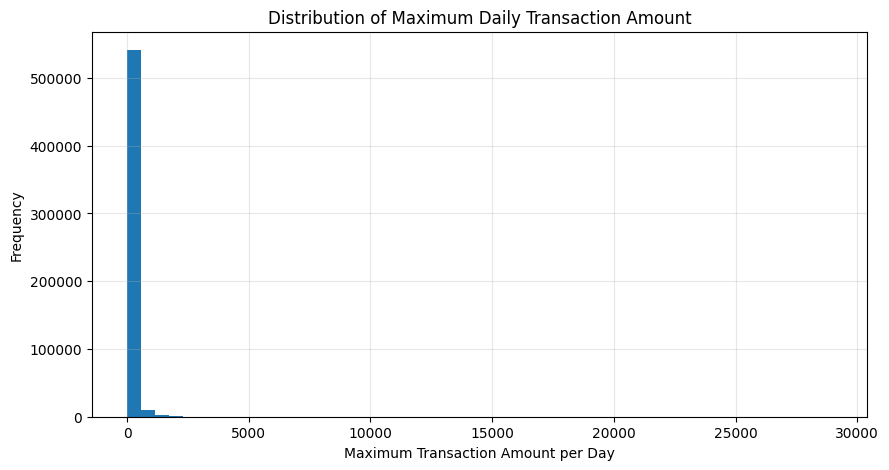

In [125]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_daily["max_amount"],
    bins=50
)

plt.title("Distribution of Maximum Daily Transaction Amount")
plt.xlabel("Maximum Transaction Amount per Day")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

#### Step 10 – Daily Standard Deviation
این قسمت برای تشخیص تغییر رفتار مشتری مهم است.

In [126]:
customer_daily["std_amount"].describe()

count    413986.000000
mean         63.182456
std         140.548559
min           0.000000
25%          23.405234
50%          38.978950
75%          64.459854
max       18767.271582
Name: std_amount, dtype: float64

#### Step 11 – Fraudulent Customer-Days

In [127]:
fraud_customer_days = customer_daily[
    customer_daily["fraud_count"] > 0
]

fraud_customer_days.head()

,cc_num,transaction_date,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count,fraud_rate
52,60416207185,2019-03-01,3,44.07,14.690000,13.170,19.16,3.936610,3,100.0
53,60416207185,2019-03-02,6,1855.66,309.276667,195.935,830.06,332.947853,6,100.0
771,60422928733,2019-04-17,6,2548.91,424.818333,307.965,988.04,435.352099,6,100.0
772,60422928733,2019-04-18,6,4951.27,825.211667,915.825,1036.43,279.908151,6,100.0
1398,60423098130,2019-03-14,7,3498.58,499.797143,317.390,1222.17,524.955429,7,100.0


In [128]:
print(
    "Customer-Days with Fraud:",
    len(fraud_customer_days)
)

Customer-Days with Fraud: 1927


#### Step 12 – Compare Fraudulent vs Normal Customer-Days

In [129]:
customer_daily["has_fraud"] = (
    customer_daily["fraud_count"] > 0
).astype(int)

In [130]:
customer_day_comparison = (
    customer_daily
    .groupby("has_fraud")[
        [
            "transaction_count",
            "total_amount",
            "average_amount",
            "max_amount",
            "std_amount"
        ]
    ]
    .mean()
)

customer_day_comparison

,transaction_count,total_amount,average_amount,max_amount,std_amount
has_fraud,,,,,
0,3.336131,225.693525,67.613439,128.723443,61.868724
1,5.008822,2657.749030,530.299900,916.305714,357.127516


#### Step 13 – Visual Comparison

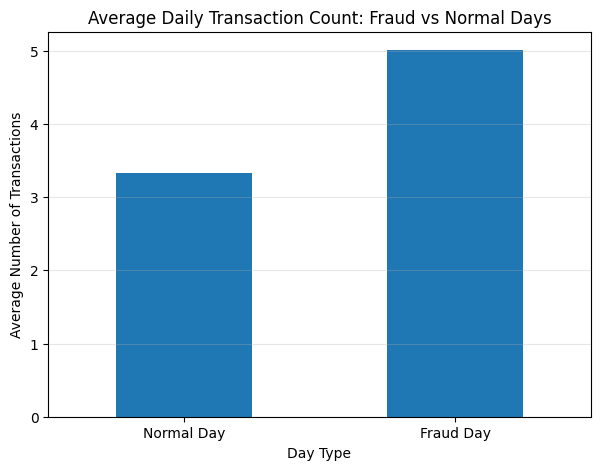

In [131]:
plt.figure(figsize=(7, 5))

customer_day_comparison["transaction_count"].plot(
    kind="bar"
)

plt.title("Average Daily Transaction Count: Fraud vs Normal Days")
plt.xlabel("Day Type")
plt.ylabel("Average Number of Transactions")

plt.xticks(
    [0, 1],
    ["Normal Day", "Fraud Day"],
    rotation=0
)

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Step 14 – Identify High-Risk Customer Days

In [132]:
high_risk_days = customer_daily[
    (customer_daily["transaction_count"] >= 10) &
    (customer_daily["fraud_count"] > 0)
].sort_values(
    by=["fraud_count", "total_amount"],
    ascending=False
)

high_risk_days.head(20)

,cc_num,transaction_date,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count,fraud_rate,has_fraud
65796,4593569795412,2019-02-25,16,7784.94,486.558750,299.880,1165.94,437.324136,16,100.0,1
86182,30074693890476,2019-02-28,16,2955.15,184.696875,21.420,788.90,277.432945,16,100.0,1
23388,630425673344,2019-02-28,15,7952.37,530.158000,758.330,1033.69,413.921069,15,100.0,1
410566,4599285557366057,2020-10-25,15,7501.72,500.114667,386.540,1034.66,387.925679,15,100.0,1
467521,6011382886333463,2019-11-02,13,7221.64,555.510769,362.920,1098.84,330.813331,13,100.0,1
330329,3573030041201292,2020-06-20,13,5220.67,401.590000,264.640,1006.04,381.290326,13,100.0,1
265914,3506042666828517,2019-12-04,12,7577.25,631.437500,743.760,1131.73,395.955436,12,100.0,1
274465,3518669219150142,2019-01-21,12,7384.76,615.396667,763.485,1122.38,416.782502,12,100.0,1
33887,676148621961,2019-07-22,12,7130.30,594.191667,727.095,1230.42,427.482468,12,100.0,1
380428,4260059589824237,2019-09-07,12,6985.43,582.119167,716.025,1114.22,378.720140,12,100.0,1


#### Step 15 – Daily Customer Behavior Summary

In [133]:
customer_daily_summary = customer_daily[
    [
        "cc_num",
        "transaction_date",
        "transaction_count",
        "total_amount",
        "average_amount",
        "median_amount",
        "max_amount",
        "std_amount",
        "fraud_count",
        "fraud_rate",
        "has_fraud"
    ]
]

customer_daily_summary.head()

,cc_num,transaction_date,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count,fraud_rate,has_fraud
0,60416207185,2019-01-01,1,7.27,7.2700,7.270,7.27,NaN,0,0.0,0
1,60416207185,2019-01-02,4,196.99,49.2475,43.865,82.08,24.410390,0,0.0,0
2,60416207185,2019-01-03,2,15.30,7.6500,7.650,8.43,1.103087,0,0.0,0
3,60416207185,2019-01-04,2,143.85,71.9250,71.925,117.11,63.901240,0,0.0,0
4,60416207185,2019-01-05,2,110.18,55.0900,55.090,105.20,70.866242,0,0.0,0


#### ُSummery
 در این بخش رفتار روزانه هر مشتری بر اساس شماره کارت (cc_num) بررسی شد. برای هر مشتری در هر روز، تعداد تراکنش‌ها، مجموع مبلغ، میانگین مبلغ، Median، حداکثر مبلغ، انحراف معیار و تعداد تراکنش‌های تقلبی محاسبه شد. سپس روزهای دارای تقلب با روزهای عادی مقایسه شدند تا مشخص شود آیا افزایش تعداد تراکنش‌ها، افزایش مبلغ تراکنش‌ها یا تغییر شدید در مبالغ روزانه با وقوع تقلب ارتباط دارد یا خیر. این تحلیل می‌تواند برای شناسایی رفتارهای غیرعادی مشتری و ایجاد ویژگی‌های مؤثر برای مدل‌های تشخیص تقلب مورد استفاده قرار گیرد.

 و همانطور که دیدیم هر چه تعداد تراکنش ها در یک روز بیتشر میشود میزان احتمال تقلب هم بالاتر میرود

### Part 11 – Amount & Transaction Interval Relationship

هدف این بخش اینه که مبلغ تراکنش و فاصله زمانی بین تراکنش‌های متوالی رو با هم بررسی کنیم و ببینیم آیا ترکیب این دو ویژگی با Fraud ارتباطی داره یا نه.


#### Step 1 – Check Required Columns

In [149]:
df[[
    "cc_num",
    "trans_date_trans_time",
    "amt",
    "time_diff_minutes",
    "is_fraud"
]].head()

,cc_num,trans_date_trans_time,amt,time_diff_minutes,is_fraud
0,2703186189652095,2019-01-01 00:00:18,4.97,NaN,0
1,630423337322,2019-01-01 00:00:44,107.23,NaN,0
2,38859492057661,2019-01-01 00:00:51,220.11,NaN,0
3,3534093764340240,2019-01-01 00:01:16,45.00,NaN,0
4,375534208663984,2019-01-01 00:03:06,41.96,NaN,0


#### Step 2 – Basic Relationship
ببنیم بین مبلغ و فاصله زمانی رابطه خطی قابل توجه ای وجود دارد یا نه.

In [150]:
df[[
    "amt",
    "time_diff_minutes"
]].corr()

,amt,time_diff_minutes
amt,1.000000,-0.002313
time_diff_minutes,-0.002313,1.000000


Correlation بین -1 و +1 است.

نزدیک +1 → رابطه مثبت قوی

نزدیک -1 → رابطه منفی قوی

نزدیک 0 → رابطه خطی ضعیف یا تقریباً وجود ندارد

#### Step 3 – Scatter Plot

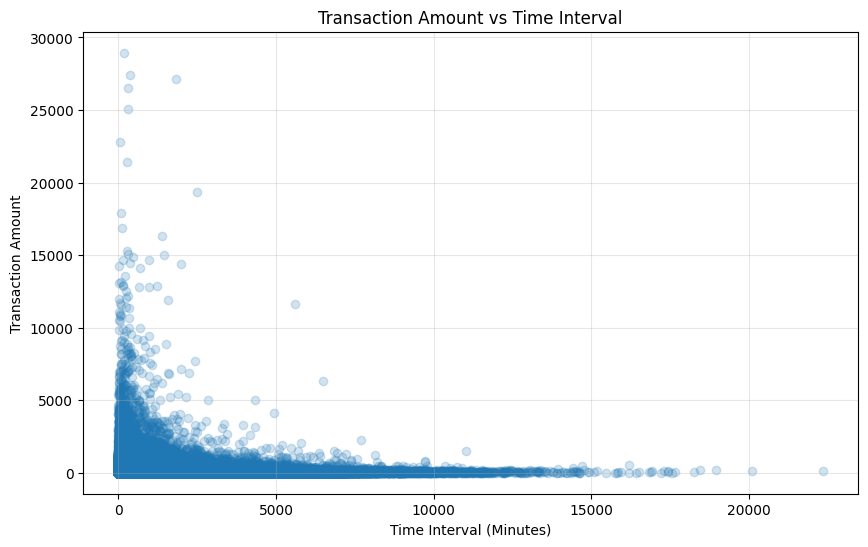

In [151]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["time_diff_minutes"],
    df["amt"],
    alpha=0.2
)

plt.xlabel("Time Interval (Minutes)")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount vs Time Interval")

plt.grid(alpha=0.3)

plt.show()

#### Step 4 – Remove Extreme Values Only for Visualization

In [152]:
plot_data = df[
    (df["time_diff_minutes"] <= 1440) &
    (df["amt"] <= df["amt"].quantile(0.99))
].copy()

#### Step 5 – Better Scatter Plot

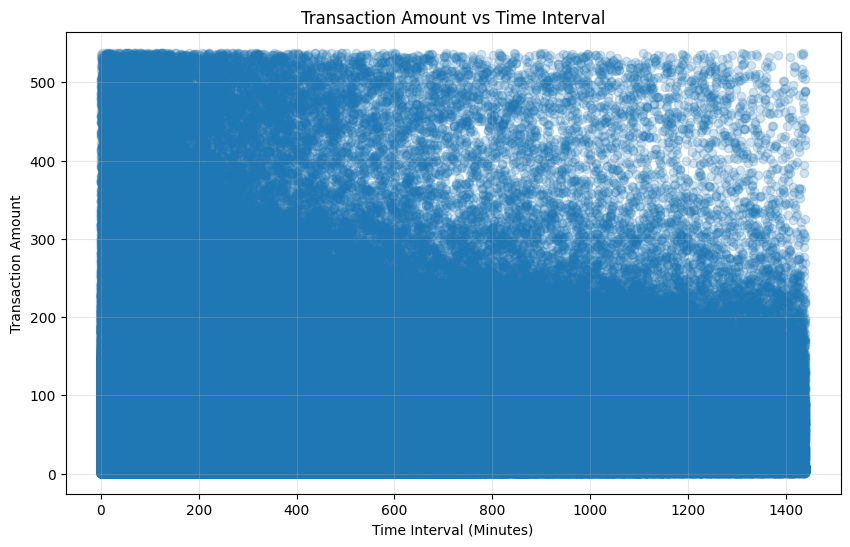

In [153]:
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["time_diff_minutes"],
    plot_data["amt"],
    alpha=0.2
)

plt.xlabel("Time Interval (Minutes)")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount vs Time Interval")
plt.grid(alpha=0.3)

plt.show()

#### Step 6 – Compare Fraud and Normal

In [154]:
normal_data = plot_data[
    plot_data["is_fraud"] == 0
]

fraud_data = plot_data[
    plot_data["is_fraud"] == 1
]

#### Step 7 – Fraud Scatter Plot

c:\Users\Legion\myenv_new\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


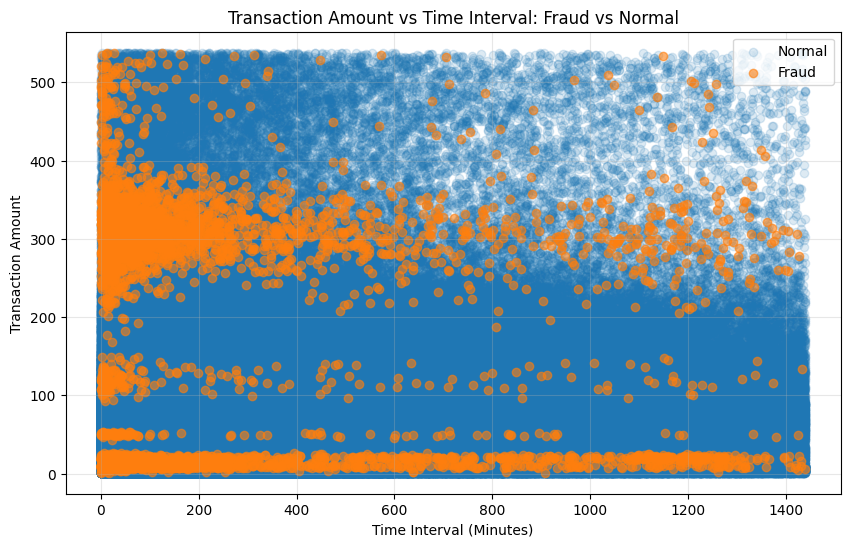

In [155]:
plt.figure(figsize=(10, 6))

plt.scatter(
    normal_data["time_diff_minutes"],
    normal_data["amt"],
    alpha=0.15,
    label="Normal"
)

plt.scatter(
    fraud_data["time_diff_minutes"],
    fraud_data["amt"],
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("Time Interval (Minutes)")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount vs Time Interval: Fraud vs Normal")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Step 8 – Create Amount Groups
مبلغ را به چند گروه تقسیم می‌کنیم

In [156]:
df["amount_group"] = pd.cut(
    df["amt"],
    bins=[
        0,
        25,
        50,
        100,
        250,
        500,
        1000,
        float("inf")
    ],
    labels=[
        "0-25",
        "25-50",
        "50-100",
        "100-250",
        "250-500",
        "500-1000",
        "1000+"
    ],
    include_lowest=True
)

#### Step 9 – Create Interval Groups
فاصله زمانی را گروه بندی میکنیم

In [157]:
df["interval_group"] = pd.cut(
    df["time_diff_minutes"],
    bins=[
        0,
        5,
        15,
        30,
        60,
        180,
        360,
        720,
        1440,
        float("inf")
    ],
    labels=[
        "0-5 min",
        "5-15 min",
        "15-30 min",
        "30-60 min",
        "1-3 hours",
        "3-6 hours",
        "6-12 hours",
        "12-24 hours",
        "24+ hours"
    ],
    include_lowest=True
)

#### Step 10 – Fraud Rate by Amount and Interval

In [158]:
amount_interval_fraud = (
    df
    .groupby(
        ["amount_group", "interval_group"],
        observed=False
    )["is_fraud"]
    .mean()
    * 100
)

amount_interval_fraud

amount_group  interval_group
0-25          0-5 min            0.782763
              5-15 min           0.663119
              15-30 min          0.578404
              30-60 min          0.496775
              1-3 hours          0.288964
                                  ...    
1000+         1-3 hours         11.977030
              3-6 hours          8.486239
              6-12 hours        14.343708
              12-24 hours       32.024540
              24+ hours          5.621302
Name: is_fraud, Length: 63, dtype: float64

#### Step 11 – Heatmap

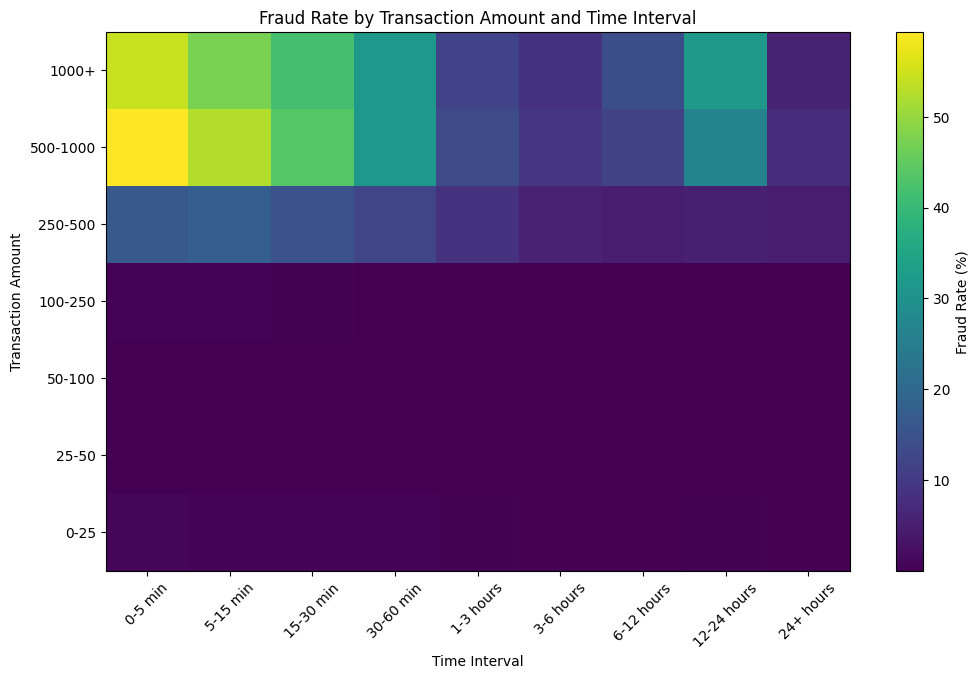

In [159]:
heatmap_data = amount_interval_fraud.unstack()

plt.figure(figsize=(12, 7))

plt.imshow(
    heatmap_data,
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Fraud Rate (%)")

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns,
    rotation=45
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.xlabel("Time Interval")
plt.ylabel("Transaction Amount")
plt.title("Fraud Rate by Transaction Amount and Time Interval")

plt.show()

هر خانه نشان‌دهنده:

نرخ تقلب برای یک محدوده مبلغ و یک محدوده فاصله زمانی

اگر این خانه Fraud Rate بالایی داشته باشد، یعنی:

تراکنش‌هایی با مبلغ ۵۰۰ تا ۱۰۰۰ و فاصله کمتر از ۵ دقیقه، نرخ تقلب بالاتری داشته‌اند.

#### Step 12 – Find Highest-Risk Combinations

In [160]:
risk_combinations = (
    amount_interval_fraud
    .dropna()
    .sort_values(ascending=False)
)

risk_combinations.head(10)

amount_group  interval_group
500-1000      0-5 min           59.325397
1000+         0-5 min           54.285714
500-1000      5-15 min          52.560976
1000+         5-15 min          47.452229
500-1000      15-30 min         43.709226
1000+         15-30 min         41.826923
              12-24 hours       32.024540
500-1000      30-60 min         31.658291
1000+         30-60 min         31.621188
500-1000      12-24 hours       26.423786
Name: is_fraud, dtype: float64

#### Step 13 – Focus on Very Short Intervals

چون یکی از رفتارهای مهم می‌تواند تراکنش‌های سریع پشت سر هم باشد، یک تحلیل جداگانه انجام می‌دهیم.

In [161]:
short_interval_data = df[
    df["time_diff_minutes"] <= 5
]

این جدول مشخص می‌کند در تراکنش‌هایی که حداکثر ۵ دقیقه با تراکنش قبلی فاصله دارند، کدام محدوده مبلغ خطر بیشتری دارد.

In [162]:
short_interval_summary = (
    short_interval_data
    .groupby("amount_group", observed=False)["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

short_interval_summary["fraud_rate"] *= 100

short_interval_summary

,transaction_count,fraud_count,fraud_rate
amount_group,,,
0-25,12392,97,0.782763
25-50,4773,3,0.062854
50-100,7938,8,0.100781
100-250,4517,31,0.686296
250-500,619,102,16.478191
500-1000,504,299,59.325397
1000+,175,95,54.285714


#### Step 14 – Important Check: Sample Size

In [163]:
risk_combinations_table = (
    df
    .groupby(
        ["amount_group", "interval_group"],
        observed=False
    )
    .agg(
        transaction_count=("is_fraud", "count"),
        fraud_count=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
)

risk_combinations_table["fraud_rate"] *= 100

risk_combinations_table = (
    risk_combinations_table
    .sort_values("fraud_rate", ascending=False)
)

risk_combinations_table.head(20)

transaction_count  fraud_count  fraud_rate
amount_group interval_group                                            
500-1000     0-5 min                       504          299   59.325397
1000+        0-5 min                       175           95   54.285714
500-1000     5-15 min                      820          431   52.560976
1000+        5-15 min                      314          149   47.452229
500-1000     15-30 min                    1073          469   43.709226
1000+        15-30 min                     416          174   41.826923
             12-24 hours                   815          261   32.024540
500-1000     30-60 min                    1592          504   31.658291
1000+        30-60 min                     623          197   31.621188
500-1000     12-24 hours                  2388          631   26.423786
250-500      5-15 min                     1168          208   17.808219
             0-5 min                       619          102   16.478191
             15-30 min                    1685          250   14.836795
1000+        6-12 hours                    739          106   14.343708
500-1000     1-3 hours                    3434          473   13.774024
250-500      30-60 min                    2935          364   12.402044
1000+        1-3 hours                    1219          146   11.977030
500-1000     6-12 hours                   2615          300   11.472275
             3-6 hours                    2701          255    9.440948
250-500      1-3 hours                    7576          646    8.526927

#### Summery

در این بخش رابطه بین مبلغ تراکنش و فاصله زمانی بین تراکنش‌های متوالی بررسی شد. ابتدا همبستگی و توزیع این دو متغیر بررسی شد و سپس رفتار تراکنش‌های عادی و تقلبی با یکدیگر مقایسه گردید. در ادامه، مبلغ و فاصله زمانی به بازه‌های مختلف تقسیم شدند و نرخ تقلب برای هر ترکیب محاسبه شد. این تحلیل کمک می‌کند الگوهای مشکوکی مانند مبالغ بالا همراه با فاصله زمانی کوتاه بین تراکنش‌ها شناسایی شوند.

### Part 12 – Customer Overall Behavior Analysis
میخواهیم ببینیم هر مشتری در کل دوره چند تراکنش داشته، چقدر پول جابه‌جا کرده، چند روز فعال بوده و آیا رفتار مشتری‌هایی که Fraud داشته‌اند با بقیه متفاوت است یا نه.

#### Step 1 – Customer-Level Aggregation

In [164]:
customer_summary = (
    df.groupby("cc_num")
    .agg(
        transaction_count=("is_fraud", "count"),
        total_amount=("amt", "sum"),
        average_amount=("amt", "mean"),
        median_amount=("amt", "median"),
        max_amount=("amt", "max"),
        std_amount=("amt", "std"),
        fraud_count=("is_fraud", "sum"),
        active_days=("transaction_date", "nunique")
    )
    .reset_index()
)

In [165]:
customer_summary.head()

,cc_num,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count,active_days
0,60416207185,2196,130130.12,59.257796,36.540,3437.46,142.869746,9,683
1,60422928733,2200,144062.95,65.483159,51.405,1290.37,92.042844,12,671
2,60423098130,738,71125.55,96.376084,35.425,27119.77,1000.693872,10,444
3,60427851591,743,79863.25,107.487550,76.670,1164.36,131.014534,14,449
4,60487002085,735,47111.24,64.096925,35.670,2758.46,153.207660,8,454


#### Step 2 – Customer Fraud Rate

In [166]:
customer_summary["fraud_rate"] = (
    customer_summary["fraud_count"]
    / customer_summary["transaction_count"]
) * 100

In [167]:
customer_summary.head()

,cc_num,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count,active_days,fraud_rate
0,60416207185,2196,130130.12,59.257796,36.540,3437.46,142.869746,9,683,0.409836
1,60422928733,2200,144062.95,65.483159,51.405,1290.37,92.042844,12,671,0.545455
2,60423098130,738,71125.55,96.376084,35.425,27119.77,1000.693872,10,444,1.355014
3,60427851591,743,79863.25,107.487550,76.670,1164.36,131.014534,14,449,1.884253
4,60487002085,735,47111.24,64.096925,35.670,2758.46,153.207660,8,454,1.088435


#### Step 3 – Distribution of Customer Transaction Count

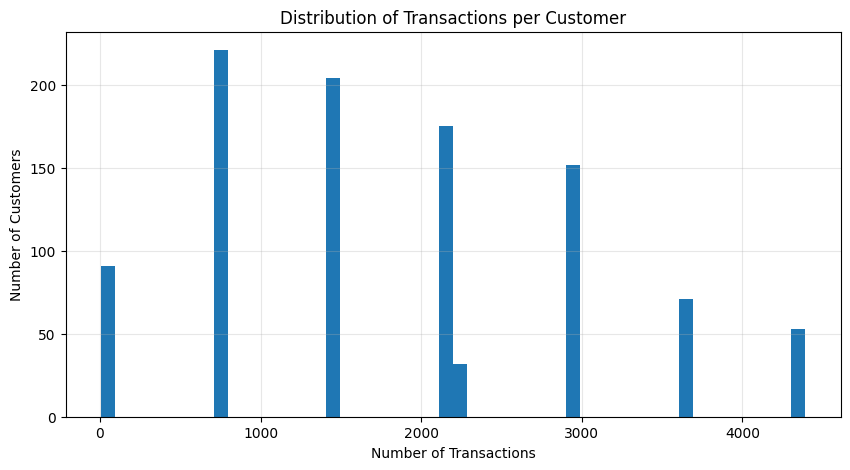

In [168]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_summary["transaction_count"],
    bins=50
)

plt.title("Distribution of Transactions per Customer")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.grid(alpha=0.3)

plt.show()                                                                                                                                                                                          

#### Step 4 – Active Days per Customer

In [169]:
customer_summary["active_days"].describe()

count    999.000000
mean     554.840841
std      201.125829
min        1.000000
25%      446.000000
50%      617.000000
75%      696.000000
max      727.000000
Name: active_days, dtype: float64

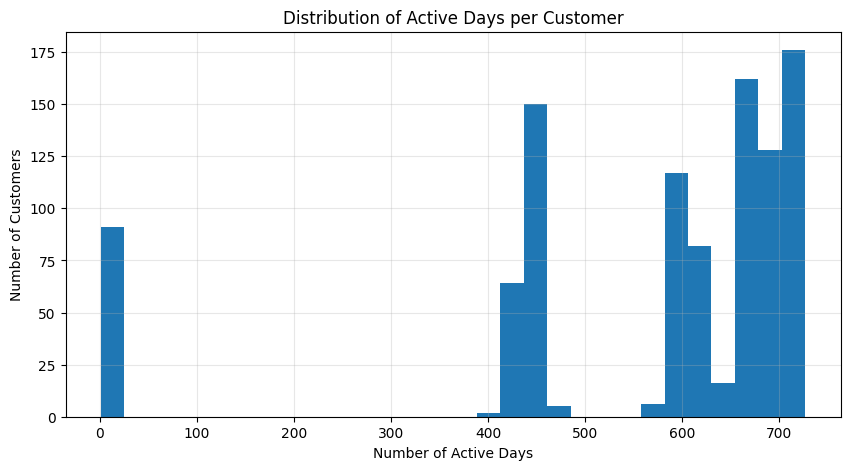

In [170]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_summary["active_days"],
    bins=30
)

plt.title("Distribution of Active Days per Customer")
plt.xlabel("Number of Active Days")
plt.ylabel("Number of Customers")

plt.grid(alpha=0.3)

plt.show()

#### Step 5 – Average Transactions per Active Day

In [171]:
customer_summary["transactions_per_day"] = (
    customer_summary["transaction_count"]
    / customer_summary["active_days"]
)

این ویژگی می‌گوید:

مشتری به طور متوسط در هر روز فعال چند تراکنش انجام داده است.

In [172]:
customer_summary[
    [
        "transaction_count",
        "active_days",
        "transactions_per_day"
    ]
].describe()

,transaction_count,active_days,transactions_per_day
count,999.000000,999.000000,999.000000
mean,1854.248248,554.840841,3.327115
std,1175.572597,201.125829,1.372194
min,6.000000,1.000000,1.592275
25%,740.000000,446.000000,2.385053
50%,1471.000000,617.000000,3.259259
75%,2917.000000,696.000000,4.179799
max,4392.000000,727.000000,9.500000


#### Step 6 – Compare Fraud vs Normal Customers

In [173]:
customer_summary["has_fraud"] = (
    customer_summary["fraud_count"] > 0
).astype(int)

In [174]:
customer_comparison = (
    customer_summary
    .groupby("has_fraud")[
        [
            "transaction_count",
            "total_amount",
            "average_amount",
            "max_amount",
            "active_days",
            "transactions_per_day"
        ]
    ]
    .mean()
)

customer_comparison

,transaction_count,total_amount,average_amount,max_amount,active_days,transactions_per_day
has_fraud,,,,,,
0,2316.956522,162315.719565,69.072070,4532.936522,644.826087,3.483809
1,1843.344262,129151.711537,120.638382,3214.090984,552.720287,3.323422


#### Step 7 – Fraud Customers vs Normal Customers

این به ما می‌گوید چه درصدی از مشتری‌ها حداقل یک تراکنش Fraud داشته‌اند.

In [175]:
customer_summary["has_fraud"].value_counts()

has_fraud
1    976
0     23
Name: count, dtype: int64

In [176]:
customer_summary["has_fraud"].value_counts(
    normalize=True
) * 100

has_fraud
1    97.697698
0     2.302302
Name: proportion, dtype: float64

#### Step 8 – High-Frequency Customers

In [177]:
high_frequency_customers = (
    customer_summary
    .sort_values(
        "transaction_count",
        ascending=False
    )
)

high_frequency_customers.head(20)

,cc_num,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count,active_days,fraud_rate,transactions_per_day,has_fraud
886,6538441737335434,4392,336174.28,76.542413,54.180,17897.24,280.989465,18,715,0.409836,6.142657,1
185,30270432095985,4392,248056.36,56.479135,33.480,5348.91,143.409210,15,719,0.341530,6.108484,1
887,6538891242532018,4386,383817.40,87.509667,52.295,1707.05,119.434081,16,723,0.364797,6.066390,1
747,4642255475285942,4386,259319.63,59.124403,34.780,4344.87,145.252330,12,722,0.273598,6.074792,1
703,4364010865167176,4386,209986.08,47.876443,21.490,4093.22,125.879842,15,715,0.341997,6.134266,1
332,344709867813900,4385,391922.65,89.378027,53.530,1510.15,123.258206,14,721,0.319270,6.081831,1
843,6011438889172900,4385,400889.15,91.422839,55.180,1962.76,132.743769,14,722,0.319270,6.073407,1
787,4904681492230012,4384,266455.17,60.779008,35.125,4951.14,153.731934,15,724,0.342153,6.055249,1
135,4745996322265,4384,332099.67,75.752662,55.670,9931.82,169.150231,10,717,0.228102,6.114365,1
959,4512828414983801773,4384,250072.42,57.042067,36.035,4304.22,122.547100,13,723,0.296533,6.063624,1


#### Step 9 – High-Amount Customers
ینجا مشتری‌هایی را می‌بینیم که در کل دوره بیشترین مبلغ تراکنش را داشته‌اند.

In [178]:
high_amount_customers = (
    customer_summary
    .sort_values(
        "total_amount",
        ascending=False
    )
)

high_amount_customers.head(20)

,cc_num,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count,active_days,fraud_rate,transactions_per_day,has_fraud
587,3566094707272327,4374,411669.98,94.117508,55.070,16837.08,284.953910,3,722,0.068587,6.058172,1
788,4908846471916297,4375,410045.55,93.724697,52.420,12176.55,262.395946,3,725,0.068571,6.034483,1
837,6011367958204270,4380,406394.34,92.784096,53.465,8524.52,191.768560,0,721,0.000000,6.074896,0
776,4836998673805450,4377,404503.72,92.415746,55.700,5160.64,165.838335,4,723,0.091387,6.053942,1
362,372509258176510,4379,401291.57,91.640002,52.720,10469.09,231.099290,8,721,0.182690,6.073509,1
843,6011438889172900,4385,400889.15,91.422839,55.180,1962.76,132.743769,14,722,0.319270,6.073407,1
456,2712209726293386,4372,396746.42,90.747123,53.370,7486.04,165.470881,5,722,0.114364,6.055402,1
627,3590736522064285,4372,394567.09,90.248648,55.340,3729.41,130.498785,8,721,0.182983,6.063800,1
332,344709867813900,4385,391922.65,89.378027,53.530,1510.15,123.258206,14,721,0.319270,6.081831,1
616,3583635130604947,4380,391381.21,89.356441,55.070,2447.75,128.102486,0,720,0.000000,6.083333,0


#### Step 10 – High Fraud Rate Customers

In [179]:
high_fraud_rate_customers = (
    customer_summary[
        customer_summary["transaction_count"] >= 10
    ]
    .sort_values(
        "fraud_rate",
        ascending=False
    )
)

high_fraud_rate_customers.head(20)

,cc_num,transaction_count,total_amount,average_amount,median_amount,max_amount,std_amount,fraud_count,active_days,fraud_rate,transactions_per_day,has_fraud
918,4180192513916047166,11,5113.92,464.901818,295.040,1143.67,429.817812,11,2,100.0,5.5,1
35,577891228931,12,8789.74,732.478333,938.565,1140.72,405.851719,12,2,100.0,6.0,1
930,4257110907449569602,10,4693.06,469.306000,317.250,1172.01,482.145942,10,2,100.0,5.0,1
42,586100864972,12,9874.94,822.911667,908.365,1135.26,320.792840,12,2,100.0,6.0,1
877,6517779374888867,11,7066.92,642.447273,725.120,1097.42,381.340103,11,2,100.0,5.5,1
917,4162872756672112717,10,6950.25,695.025000,723.620,1167.88,331.547707,10,2,100.0,5.0,1
865,6011935564104173,11,10437.00,948.818182,972.280,1124.34,225.564782,11,2,100.0,5.5,1
108,4457486401506,10,6263.21,626.321000,835.205,1100.75,433.519561,10,2,100.0,5.0,1
540,3543885983111461,11,8564.29,778.571818,874.980,1111.80,325.420022,11,2,100.0,5.5,1
550,3548710338694745,12,8350.56,695.880000,860.115,1160.47,408.494447,12,2,100.0,6.0,1


#### Step 11 – Customer Transaction Frequency vs Fraud
حالا ببینیم تعداد تراکنش‌های مشتری چه ارتباطی با Fraud Rate دارد.

In [180]:
customer_summary["transaction_group"] = pd.cut(
    customer_summary["transaction_count"],
    bins=[0, 5, 10, 20, 50, 100, 200, float("inf")],
    labels=[
        "1-5",
        "6-10",
        "11-20",
        "21-50",
        "51-100",
        "101-200",
        "200+"
    ]
)

In [181]:
customer_frequency_fraud = (
    customer_summary
    .groupby(
        "transaction_group",
        observed=False
    )["fraud_rate"]
    .mean()
)

customer_frequency_fraud

transaction_group
1-5               NaN
6-10       100.000000
11-20      100.000000
21-50             NaN
51-100            NaN
101-200           NaN
200+         0.653351
Name: fraud_rate, dtype: float64

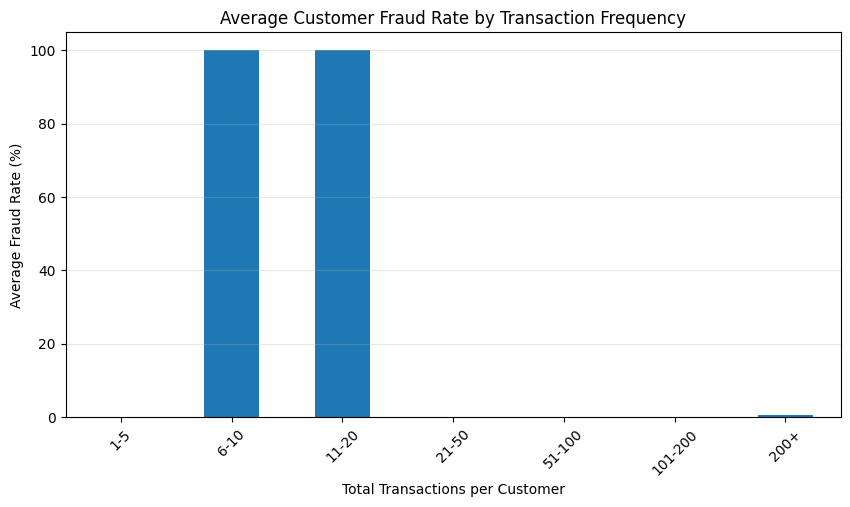

In [182]:
plt.figure(figsize=(10, 5))

customer_frequency_fraud.plot(kind="bar")

plt.title("Average Customer Fraud Rate by Transaction Frequency")
plt.xlabel("Total Transactions per Customer")
plt.ylabel("Average Fraud Rate (%)")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Step 12 – Customer Activity vs Fraud

In [183]:
active_days_fraud = (
    customer_summary
    .groupby("has_fraud")[
        [
            "active_days",
            "transactions_per_day"
        ]
    ]
    .mean()
)

active_days_fraud

,active_days,transactions_per_day
has_fraud,,
0,644.826087,3.483809
1,552.720287,3.323422


#### Step 13 – Final Customer-Level Table

In [184]:
customer_behavior = customer_summary[
    [
        "cc_num",
        "transaction_count",
        "active_days",
        "transactions_per_day",
        "total_amount",
        "average_amount",
        "median_amount",
        "max_amount",
        "std_amount",
        "fraud_count",
        "fraud_rate",
        "has_fraud"
    ]
]

### Part 13 - Holiday

#### Step 1 - Holiday Detection

In [185]:
df["state"].value_counts().head(20)

state
TX    135269
NY    119419
PA    114173
CA     80495
OH     66627
MI     65825
IL     62212
FL     60775
AL     58521
MO     54904
MN     45433
AR     44611
NC     43134
VA     41756
WI     41738
SC     41731
KY     40981
IN     39539
IA     38804
OK     38050
Name: count, dtype: int64

In [186]:
us_holidays = holidays.US(years=[2019, 2020])

In [187]:
df['holiday_name'] = df['trans_date_trans_time'].dt.date.map(us_holidays)

df['is_holiday'] = df['holiday_name'].notna()

In [188]:
df[['trans_date_trans_time', 'holiday_name', 'is_holiday']].head(20)

,trans_date_trans_time,holiday_name,is_holiday
0,2019-01-01 00:00:18,New Year's Day,True
1,2019-01-01 00:00:44,New Year's Day,True
2,2019-01-01 00:00:51,New Year's Day,True
3,2019-01-01 00:01:16,New Year's Day,True
4,2019-01-01 00:03:06,New Year's Day,True
5,2019-01-01 00:04:08,New Year's Day,True
6,2019-01-01 00:04:42,New Year's Day,True
7,2019-01-01 00:05:08,New Year's Day,True
8,2019-01-01 00:05:18,New Year's Day,True
9,2019-01-01 00:06:01,New Year's Day,True


In [189]:
print(df['is_holiday'].value_counts())

is_holiday
False    1796809
True       55585
Name: count, dtype: int64


#### Step 2 - Holiday Fraud Rate

In [190]:
df.columns.tolist()

['Unnamed: 0',
 'trans_date_trans_time',
 'cc_num',
 'merchant',
 'category',
 'amt',
 'first',
 'last',
 'gender',
 'street',
 'city',
 'state',
 'zip',
 'lat',
 'long',
 'city_pop',
 'job',
 'dob',
 'trans_num',
 'unix_time',
 'merch_lat',
 'merch_long',
 'is_fraud',
 'year',
 'month',
 'month_name',
 'day',
 'hour',
 'day_of_week',
 'day_name',
 'is_weekend',
 'transaction_date',
 'time_period',
 'time_diff_minutes',
 'amount_group',
 'interval_group',
 'holiday_name',
 'is_holiday']

In [191]:
holiday_df = df[df['is_holiday']]

total_transactions = len(holiday_df)

fraud_transactions = holiday_df['is_fraud'].sum()

fraud_rate = (fraud_transactions / total_transactions) * 100

print("Total holiday transactions:", total_transactions)
print("Fraud transactions on holidays:", fraud_transactions)
print("Holiday fraud rate:", round(fraud_rate, 4), "%")

Total holiday transactions: 55585
Fraud transactions on holidays: 258
Holiday fraud rate: 0.4642 %


#### Step 3 - Holiday vs. Normal Day

In [192]:
normal_df = df[~df['is_holiday']]

total_normal_transactions = len(normal_df)

fraud_normal_transactions = normal_df['is_fraud'].sum()

normal_fraud_rate = (
    fraud_normal_transactions / total_normal_transactions
) * 100

print("Total normal-day transactions:", total_normal_transactions)
print("Fraud transactions on normal days:", fraud_normal_transactions)
print("Normal-day fraud rate:", round(normal_fraud_rate, 4), "%")

Total normal-day transactions: 1796809
Fraud transactions on normal days: 9393
Normal-day fraud rate: 0.5228 %


In [193]:
holiday_rate = 0.4642
normal_rate = 0.5228

risk_ratio = holiday_rate / normal_rate

print("Risk Ratio:", round(risk_ratio, 3))

Risk Ratio: 0.888


In [194]:
holiday_analysis = (
    df[df['is_holiday']]
    .groupby('holiday_name')['is_fraud']
    .agg(
        total_transactions='count',
        fraud_transactions='sum'
    )
    .reset_index()
)

holiday_analysis['fraud_rate'] = (
    holiday_analysis['fraud_transactions']
    / holiday_analysis['total_transactions']
) * 100

holiday_analysis = holiday_analysis.sort_values(
    'fraud_rate',
    ascending=False
)

holiday_analysis['fraud_rate'] = holiday_analysis['fraud_rate'].round(4)
holiday_analysis

,holiday_name,total_transactions,fraud_transactions,fraud_rate
8,Thanksgiving Day,3481,49,1.4076
3,Independence Day (observed),2276,14,0.6151
10,Washington's Birthday,4783,28,0.5854
5,Martin Luther King Jr. Day,4691,27,0.5756
1,Columbus Day,6330,36,0.5687
6,Memorial Day,7712,37,0.4798
9,Veterans Day,4549,21,0.4616
2,Independence Day,4682,14,0.2990
4,Labor Day,6450,18,0.2791
0,Christmas Day,6923,11,0.1589


## Summery




### 1. Feature Engineering
برای انجام تحلیل‌های اکتشافی دقیق‌تر، Featureهای تحلیلی زیر از روی داده‌های خام استخراج و استفاده شده‌اند (بر اساس متغیرهای محور نمودارها):

- **Time Features:**
  - `Hour of Day`: ساعت وقوع تراکنش (۰ تا ۲۳)
  - `Day of Week`: روز وقوع تراکنش در هفته (دوشنبه تا یکشنبه)
  - `Month`: ماه وقوع تراکنش
  - `Time Interval (Minutes)`: فاصله زمانی بین تراکنش متوالی یک مشتری به دقیقه
  - `Weekend vs Weekday`: دسته‌بندی روز به آخر هفته یا روز کاری
- **Customer Behavior Features:**
  - `Total Transactions per Customer`: تعداد کل تراکنش‌های یک مشتری
  - `Active Days`: تعداد روزهای فعال هر مشتری
  - `Transactions per Day`: تعداد تراکنش‌های روزانه هر مشتری
- **Amount Features:**
  - `Daily Transaction Amount`: مجموع مبلغ تراکنش‌های روزانه یک مشتری
  - `Maximum Daily Transaction Amount`: حداکثر مبلغ تراکنش در یک روز برای مشتری

### 2. Exploratory Data Analysis (EDA)

<div dir='rtl'>

<b>Distribution & Skewness</b> <br> <br>

1. توزیع تعداد تراکنش‌های هر مشتری دارای کشیدگی به راست (Right-skewed) است؛ بیشترین تراکم مشتریان (بیش از ۲۱۰ نفر) حدود ۹۰۰ تراکنش داشته‌اند و با افزایش یا کاهش تعداد تراکنش‌ها، تعداد مشتریان کاهش می‌یابد. <br>

2. توزیع روزهای فعال مشتریان نیز راست‌کج است. حدود ۹۰ مشتری صفر روز فعال داشته‌اند، اما تجمع مشتریان در روزهای فعال بالاتر دیده می‌شود (حدود ۱۵۰ مشتری بین ۴۰۰ تا ۵۰۰ روز، و تجمع بالای ۱۰۰ نفر در بازه ۶۰۰ تا ۷۰۰ روز). <br>

3. توزیع مجموع مبالغ تراکنش‌های روزانه به شدت راست‌کج است؛ داده‌ها (با فرکانسی نزدیک به ۵۰۰ هزار) در محدوده مبالغ پایین (نزدیک به صفر) تجمع یافته‌اند و در بازه مبالغ بالاتر (تا سقف ۳۰٬۰۰۰) فرکانس تقریباً صفر است. <br>

4. توزیع حداکثر مبلغ تراکنش در روز نیز الگوی مشابهی دارد و به شدت راست‌کج است؛ در اکثر روزها، حداکثر مبلغ تراکنش بسیار پایین است و مبالغ بالا تنها در روزهای معدودی رخ می‌دهند. <br>

5. توزیع فاصله زمانی بین تراکنش‌های متوالی دارای کشیدگی به راست است؛ بیشترین فرکانس (بیش از ۱۶۰ هزار بار) در فواصل زمانی کوتاه (۰ تا ۲۰۰ دقیقه) رخ می‌دهد و با افزایش فاصله زمانی، تعداد تراکنش‌ها به شدت کاهش می‌یابد. <br>
<br>


<b>Time-Based Analysis</b> <br> <br>

6. روند تعداد تراکنش‌های روزانه در بازه زمانی ژانویه ۲۰۱۹ تا ژانویه ۲۰۲۱ نوسانات مداومی داشته و بین ۱۰۰۰ تا ۶۵۰۰ تراکنش در روز در حال نوسان است. <br>
7. استفاده از میانگین متحرک ۷ روزه (7-day Moving Average) نشان می‌دهد که علی‌رغم نوسانات شدید روزانه، روند کلی و میانگین حجم تراکنش‌ها در طول این دو سال نسبتاً پایدار بوده است. <br>

8. در تحلیل ماهانه، دسامبر (December) با نزدیک به ۲۸۰٬۰۰۰ تراکنش بیشترین حجم را داشته و فوریه (February) با حدود ۱۰۰٬۰۰۰ تراکنش کمترین حجم را داراست، که نشان‌دهنده الگوی فصلی در تراکنش‌هاست. <br>

9. نرخ تقلب در ماه‌های مختلف سال نوسان دارد و از الگوی یکنواخت پیروی نمی‌کند. <br>

10. بیشترین تعداد تراکنش‌ها در روزهای دوشنبه، شنبه و یکشنبه رخ می‌دهد، در حالی که کمترین تعداد تراکنش‌ها مربوط به روزهای چهارشنبه است. <br>

11. بالاترین نرخ تقلب در روزهای چهارشنبه و پنجشنبه (حدود ۶۴٪) رخ می‌دهد و پایین‌ترین نرخ تقلب مربوط به روزهای دوشنبه (حدود ۴۰٪) است. <br>

12. تفاوت نرخ تقلب بین روزهای کاری (Weekday) و آخر هفته (Weekend) بسیار ناچیز است؛ نرخ تقلب در روزهای کاری حدود ۰.۵۳٪ و در آخر هفته حدود ۰.۵۱٪ است. <br>

13. تعداد تراکنش‌های ساعتی در بازه ۰ تا ۱۰ صبح حدود ۶۰٬۰۰۰ است، اما از ساعت ۱۱ به شدت افزایش یافته و بین ساعات ۱۲ تا ۱۹ پایدار می‌ماند (حدود ۹۲٬۰۰۰ تا ۹۵٬۰۰۰). از ساعت ۲۰ به بعد روند صعودی ملایمی داشته و به نزدیک ۹۶٬۰۰۰ می‌رسد. <br>

14. بیشترین تعداد تراکنش‌های تقلبی در ساعات ۰ تا ۳ بامداد (حدود ۸۰۰ تراکنش) و سپس ساعت ۲۲ (با جهش به حدود ۲۵۰۰ تراکنش) رخ می‌دهد. در ساعات ۵ تا ۲۱ تعداد تقلب‌ها در پایین‌ترین سطح خود (زیر ۱۰۰) قرار دارد. <br>

15. نرخ تقلب در ساعات ۰ تا ۳ بامداد حدود ۱.۴٪ است، در ساعات ۴ تا ۲۰ به نزدیک صفر کاهش می‌یابد، و سپس در بازه ۲۱ تا ۲۲ ساعت به بالاترین سطح خود (حدود ۲.۶٪) می‌رسد. <br>
<br>

<b>Customer Daily Behavior</b> <br><br>

16. اکثر مشتریان در روز تعداد تراکنش‌های کمی (زیر ۱۰ تراکنش) دارند؛ به طوری که بیشترین فرکانس (حدود ۲۶۰ هزار) مربوط به ۰ تا ۲ تراکنش در روز است. <br>

17. نرخ تقلب با افزایش تعداد تراکنش‌های روزانه ابتدا افزایش می‌یابد و در روزهایی که مشتری ۷ تا ۸ تراکنش انجام داده، به حدود ۱۰۰٪ می‌رسد. <br>

18. پس از ۸ تراکنش در روز، نرخ تقلب روند نزولی به خود می‌گیرد (در ۱۵ تراکنش حدود ۴۰٪) و از ۱۷ تراکنش به بعد به نزدیک صفر رسیده و پایدار می‌ماند. <br>

19. میانگین تعداد تراکنش‌های روزانه در روزهای عادی (Normal Day) حدود ۳.۴ تراکنش است، اما این عدد در روزهایی که تقلب رخ داده (Fraud Day) به طور قابل توجهی افزایش یافته و به حدود ۵ تراکنش می‌رسد. <br>
<br>

<b>Transaction Interval Analysis</b> <br><br>

20. تراکنش‌های تقلبی (Fraud) فاصله زمانی بسیار کوتاه‌تری نسبت به تراکنش‌های عادی (Normal) دارند. میانه فاصله زمانی در تراکنش‌های عادی حدود ۲۵۰ دقیقه (با بازه وسیع ۵۰ تا ۱۴۵۰ دقیقه) است، در حالی که این میانه برای تراکنش‌های تقلبی حدود ۷۰ دقیقه (با بازه ۱۰ تا ۱۱۷۰ دقیقه) است. <br>

21. نرخ تقلب رابطه عکس با فاصله زمانی بین تراکنش‌ها دارد. بالاترین نرخ تقلب (حدود ۲.۰۵٪) در فواصل زمانی بسیار کوتاه (۰ تا ۵ دقیقه) رخ می‌دهد. با افزایش فاصله زمانی، نرخ تقلب کاهش می‌یابد؛ به طوری که در بازه ۱۵ تا ۳۰ دقیقه به ۱.۳۷٪ و در بازه ۳ تا ۶ ساعت به ۰.۲۳٪ می‌رسد. <br>

<br>

<b>Amount vs Time Interval</b> <br><br>

22. بین مبلغ تراکنش و فاصله زمانی همبستگی منفی وجود دارد. در فواصل زمانی کوتاه، مبالغ تراکنش‌ها عمدتاً در محدوده ۵۰۰ تا ۵۵۰ متمرکز هستند، اما با افزایش فاصله زمانی (به‌ویژه پس از ۴۰۰ دقیقه) مبلغ تراکنش‌ها کاهش می‌یابد و در فواصل ۱۲۰۰ تا ۱۴۰۰ دقیقه به زیر ۳۰۰ می‌رسد. <br>

23. الگوی پراکندگی تراکنش‌های تقلبی در مقایسه با تراکنش‌های عادی متمرکزتر است؛ تراکنش‌های تقلبی در نواحی خاصی از زمان و مبلغ تجمع یافته‌اند (به ویژه مبالغ پایین تا متوسط)، در حالی که تراکنش‌های عادی نواحی وسیع‌تری را پوشش می‌دهند. <br>

24. نقشه حرارتی (Heatmap) نشان می‌دهد که بالاترین نرخ تقلب در ترکیب «مبالغ بالا» و «فواصل زمانی بسیار کوتاه» (مثلاً فاصله ۰.۵ دقیقه و مبلغ بین ۵۰۰ تا ۱۰۰۰) رخ می‌دهد. در مقابل، ترکیب «مبالغ پایین» و «فواصل زمانی طولانی» (بیش از ۲۴ ساعت) کمترین نرخ تقلب را دارد. <br>
<br>

<b>Customer Overall Behavior</b> <br> <br>

25. بالاترین نرخ تقلب (نزدیک به ۱۰۰٪) در سطح مشتری، متعلق به افرادی است که در مجموع بین ۶ تا ۱۰ و ۱۱ تا ۲۰ تراکنش داشته‌اند. <br>

26. نرخ تقلب برای سایر بازه‌های تعداد تراکنش (۱-۵، ۲۱-۵۰، ۵۱-۱۰۰ و ۱۰۱-۲۰۰) تقریباً صفر است و در بازه ۲۰۰+ به عددی تک‌رقمی کاهش می‌یابد. <br>

</div>

### 3. EDA Findings
مهم‌ترین یافته‌های این تحلیل را می‌توان در موارد زیر خلاصه کرد:

- **زمان‌های پرخطر:** تراکنش‌های تقلبی تمایل زیادی به وقوع در نیمه اول شب و بامداد (ساعات ۲۱ تا ۰۳) دارند.

- **سرعت تراکنش:** کوتاه بودن فاصله زمانی بین تراکنش‌ها (زیر ۵ دقیقه) قوی‌ترین نشانگر تقلب است. تقلب‌ها معمولاً با سرعت بالایی و در فواصل زمانی بسیار کوتاه‌تر از تراکنش‌های عادی رخ می‌دهند.

- **رفتار روزانه:** روزهایی که در آن‌ها تقلب رخ داده، میانگین تعداد تراکنش‌های مشتری به شدت بالاتر (۵ تراکنش در برابر ۳.۴ تراکنش) از روزهای عادی است.

- **مشتریان هدف:** مشتریانی که سابقه تراکنش کمی دارند (بین ۶ تا ۲۰ تراکنش در کل) بیشترین نرخ تقلب را دارا هستند.

- **ترکیب مبلغ و زمان:** تراکنش‌های با مبالغ بالا که در فواصل زمانی بسیار کوتاه انجام می‌شوند، بالاترین احتمال تقلب را دارند.


### 4. Results & Discussion
نتایج این تحلیل نشان می‌دهد که رفتار تراکنش‌های تقلبی به شدت از الگوهای نرمال فاصله دارد. تبهکاران تمایل دارند در زمان‌های خاصی از شبانه‌روز (ساعات پایانی شب) و با فواصل زمانی بسیار کوتاه، تراکنش‌های با مبلغ نسبتاً بالا را انجام دهند. همچنین، نرخ بالای تقلب در روزهایی که تعداد تراکنش‌های مشتری افزایش می‌یابد (حدود ۷ تراکنش در روز)، نشان‌دهنده تلاش سریع برای نقد کردن حساب پیش از مسدود شدن آن است. این یافته‌ها چارچوب بسیار محکمی برای تعریف قوانین ساده (Rule-based Systems) یا طراحی Features قدرتمند برای مدل‌های یادگیری ماشین در آینده فراهم می‌کنند.
uirements.txt
```

   ```

In [201]:
df.to_csv("combined.csv", index=False)
print("combined.csv updated successfully!")

combined.csv updated successfully!
